# Copper Markforged DoE Notebook

This notebook contains the current `MF1`-`MF16` response-surface design for the Markforged copper specimens. It keeps **mass** and **density** as separate responses and excludes the failed preliminary `MF3 (previous)` print from regression.

The active factors are layer height, flow ratio, and nozzle temperature. `MF8`, `MF15`, and `MF16` are independently printed center-point specimens. Once at least two of them have measurements, they provide replicate-based pure experimental error.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ffd_utils import (
    build_factor_level_coverage,
    build_model_anova_table,
    build_term_significance_table,
    calculate_pure_error_from_replicates,
    fit_main_effect_screening_model,
    fit_quadratic_response_surface,
    plot_augmented_main_effects,
    plot_augmented_model_pareto,
    plot_augmented_residuals,
    plot_model_anova,
    plot_quadratic_interaction_profiles,
    plot_quadratic_surface_and_contour_pairs,
    plot_screening_half_normal,
    plot_three_level_interaction_means,
)
from notebook_plot_saver import configure_notebook_plot_saving

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "notebook_plot_saver.py").exists():
    PROJECT_ROOT = PROJECT_ROOT / "3D_Printing_Project"

FIGURE_ROOT = configure_notebook_plot_saving(
    PROJECT_ROOT / "notebook_figures",
    default_series="08_Copper_Markforged",
)
MATRIX_OUTPUT_DIR = PROJECT_ROOT / "doe_matrices" / "Copper_Markforged"
MATRIX_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SIGNIFICANCE_ALPHA = 0.05

MARKFORGED_FONT_SIZE = 13
MARKFORGED_TICK_SIZE = 12
MARKFORGED_TITLE_SIZE = 15
MARKFORGED_SUPTITLE_SIZE = 18
plt.rcParams.update({
    "font.size": MARKFORGED_FONT_SIZE,
    "axes.labelsize": MARKFORGED_FONT_SIZE,
    "axes.titlesize": MARKFORGED_TITLE_SIZE,
    "xtick.labelsize": MARKFORGED_TICK_SIZE,
    "ytick.labelsize": MARKFORGED_TICK_SIZE,
    "legend.fontsize": MARKFORGED_TICK_SIZE,
    "figure.titlesize": MARKFORGED_SUPTITLE_SIZE,
})

print(f"Figures: {FIGURE_ROOT / '08_Copper_Markforged'}")
print(f"Design tables: {MATRIX_OUTPUT_DIR.resolve()}")

Figures: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures\08_Copper_Markforged
Design tables: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_Markforged


## 2. Factor levels

The coded levels are $-1$, $0$, and $+1$. Flow ratio is dimensionless.

In [2]:
FACTOR_DEFINITIONS = [
    {
        "code": "A",
        "model_column": "A_layer_height",
        "real_column": "layer_height_mm",
        "factor": "Layer height",
        "unit": "mm",
        "low": 0.15,
        "center": 0.20,
        "high": 0.25,
    },
    {
        "code": "B",
        "model_column": "B_flow_ratio",
        "real_column": "flow_ratio",
        "factor": "Flow ratio",
        "unit": "-",
        "low": 1.10,
        "center": 1.20,
        "high": 1.30,
    },
    {
        "code": "C",
        "model_column": "C_nozzle_temp",
        "real_column": "nozzle_temperature_C",
        "factor": "Nozzle temperature",
        "unit": "deg C",
        "low": 235.0,
        "center": 245.0,
        "high": 255.0,
    },
]

FACTOR_COLUMNS = [definition["model_column"] for definition in FACTOR_DEFINITIONS]
LEVELS = {
    definition["model_column"]: {
        -1: definition["low"],
        0: definition["center"],
        1: definition["high"],
    }
    for definition in FACTOR_DEFINITIONS
}

factor_levels = pd.DataFrame(FACTOR_DEFINITIONS).rename(
    columns={
        "code": "Code",
        "factor": "Factor",
        "unit": "Unit",
        "low": "Low (-1)",
        "center": "Center (0)",
        "high": "High (+1)",
    }
)
display(factor_levels[["Code", "Factor", "Unit", "Low (-1)", "Center (0)", "High (+1)"]])

,Code,Factor,Unit,Low (-1),Center (0),High (+1)
0,A,Layer height,mm,0.15,0.2,0.25
1,B,Flow ratio,-,1.10,1.2,1.30
2,C,Nozzle temperature,deg C,235.00,245.0,255.00


## 3. DoE matrix and available measurements

Blank responses are planned specimens that have not yet been measured. Relative density is retained as descriptive metadata from the worksheet; density in `g/cm3` is the response used for regression. The separate `First_Test` print is retained as preliminary metadata and is not included in the DoE regression.

In [3]:
RUNS = [
    {"Run": "MF1",  "layer_height_mm": 0.20, "flow_ratio": 1.10, "nozzle_temperature_C": 245, "mass_g": 61.330, "archimedes_mass_g": 59.01, "density_g_cm3": 5.94, "relative_density_percent": 95.1774194, "notes": "First-layer line missing"},
    {"Run": "MF2",  "layer_height_mm": 0.15, "flow_ratio": 1.10, "nozzle_temperature_C": 235, "mass_g": 60.533, "archimedes_mass_g": 58.26, "density_g_cm3": 5.93, "relative_density_percent": 95.0214067, "notes": "Some internal lines missing due to feedstock"},
    {"Run": "MF3",  "layer_height_mm": 0.15, "flow_ratio": 1.30, "nozzle_temperature_C": 245, "mass_g": 63.445, "archimedes_mass_g": 61.03, "density_g_cm3": 5.90, "relative_density_percent": 94.5285576, "notes": "Replacement for failed preliminary MF3"},
    {"Run": "MF4",  "layer_height_mm": 0.20, "flow_ratio": 1.20, "nozzle_temperature_C": 255, "mass_g": 63.747, "archimedes_mass_g": 61.33, "density_g_cm3": 5.95, "relative_density_percent": 95.3624879, "notes": ""},
    {"Run": "MF5",  "layer_height_mm": 0.15, "flow_ratio": 1.10, "nozzle_temperature_C": 255, "mass_g": 61.140, "archimedes_mass_g": 58.83, "density_g_cm3": 5.94, "relative_density_percent": 95.2712551, "notes": ""},
    {"Run": "MF6",  "layer_height_mm": 0.25, "flow_ratio": 1.20, "nozzle_temperature_C": 245, "mass_g": 64.391, "archimedes_mass_g": 61.97, "density_g_cm3": 5.93, "relative_density_percent": 94.9731801, "notes": ""},
    {"Run": "MF7",  "layer_height_mm": 0.25, "flow_ratio": 1.10, "nozzle_temperature_C": 235, "mass_g": 62.792, "archimedes_mass_g": 60.41, "density_g_cm3": 5.89, "relative_density_percent": 94.4828935, "notes": ""},
    {"Run": "MF8",  "layer_height_mm": 0.20, "flow_ratio": 1.20, "nozzle_temperature_C": 245, "mass_g": 63.959, "archimedes_mass_g": 61.54, "density_g_cm3": 5.95, "relative_density_percent": 95.4108527, "notes": "Center-point replicate 1"},
    {"Run": "MF9",  "layer_height_mm": 0.20, "flow_ratio": 1.20, "nozzle_temperature_C": 235, "mass_g": 62.244, "archimedes_mass_g": 59.90, "density_g_cm3": 5.94, "relative_density_percent": 95.1737835, "notes": "Prints really well, but hole at corners; print again"},
    {"Run": "MF10", "layer_height_mm": 0.20, "flow_ratio": 1.30, "nozzle_temperature_C": 255, "mass_g": 64.743, "archimedes_mass_g": 62.29, "density_g_cm3": 5.95, "relative_density_percent": 95.3722488, "notes": ""},
    {"Run": "MF11", "layer_height_mm": 0.25, "flow_ratio": 1.30, "nozzle_temperature_C": 245, "mass_g": 64.153, "archimedes_mass_g": 61.71, "density_g_cm3": 5.92, "relative_density_percent": 94.8472622, "notes": ""},
    {"Run": "MF12", "layer_height_mm": 0.20, "flow_ratio": 1.30, "nozzle_temperature_C": 235, "mass_g": 64.946, "archimedes_mass_g": 62.48, "density_g_cm3": 5.93, "relative_density_percent": 95.1170314, "notes": ""},
    {"Run": "MF13", "layer_height_mm": 0.15, "flow_ratio": 1.20, "nozzle_temperature_C": 245, "mass_g": 62.516, "archimedes_mass_g": 60.16, "density_g_cm3": 5.94, "relative_density_percent": 95.2087043, "notes": ""},
    {"Run": "MF14", "layer_height_mm": 0.25, "flow_ratio": 1.10, "nozzle_temperature_C": 255, "mass_g": 62.442, "archimedes_mass_g": 60.08, "density_g_cm3": 5.94, "relative_density_percent": 95.1762376, "notes": ""},
    {"Run": "MF15", "layer_height_mm": 0.20, "flow_ratio": 1.20, "nozzle_temperature_C": 245, "mass_g": 64.327, "archimedes_mass_g": 61.90, "density_g_cm3": 5.94, "relative_density_percent": 95.2307692, "notes": "Center-point replicate 2"},
    {"Run": "MF16", "layer_height_mm": 0.20, "flow_ratio": 1.20, "nozzle_temperature_C": 245, "mass_g": 64.456, "archimedes_mass_g": 62.01, "density_g_cm3": 5.95, "relative_density_percent": 95.4, "notes": "Center-point replicate 3"},
]

FAILED_ATTEMPTS = [
    {
        "Run": "MF3 (previous)",
        "layer_height_mm": 0.15,
        "flow_ratio": 1.00,
        "nozzle_temperature_C": 245,
        "status": "Excluded",
        "notes": "Impossible print: holes between lines",
    }
]

PRELIMINARY_TESTS = [
    {
        "Run": "First_Test",
        "nozzle_temperature_C": 245,
        "layer_height_mm": 0.20,
        "speed_mm_s": 15,
        "flow_ratio": 1.20,
        "infill_percent": 100,
        "fan_percent": 30,
        "mass_g": 63.970,
        "density_g_cm3": np.nan,
        "approx_volume_cm3": 10.3,
        "status": "Preliminary; excluded from DoE regression",
    }
]

CONFIRMATION_RUNS = [
    {"Run": "MF17", "layer_height_mm": 0.21, "flow_ratio": 1.18, "nozzle_temperature_C": 255, "mass_g": np.nan, "archimedes_mass_g": 61.61, "density_g_cm3": 5.94, "relative_density_percent": 95.15058, "role": "Candidate replicate 1", "status": "Archimedes density measured; precision mass pending"},
    {"Run": "MF18", "layer_height_mm": 0.20, "flow_ratio": 1.20, "nozzle_temperature_C": 245, "mass_g": 64.592, "archimedes_mass_g": 62.15, "density_g_cm3": 5.94, "relative_density_percent": 95.24904, "role": "Same-batch center control", "status": "Mass and Archimedes density measured"},
    {"Run": "MF19", "layer_height_mm": 0.21, "flow_ratio": 1.18, "nozzle_temperature_C": 255, "mass_g": np.nan, "archimedes_mass_g": 61.69, "density_g_cm3": 5.94, "relative_density_percent": 95.27413, "role": "Candidate replicate 2", "status": "Archimedes density measured; precision mass pending"},
    {"Run": "MF20", "layer_height_mm": 0.21, "flow_ratio": 1.18, "nozzle_temperature_C": 255, "mass_g": 64.153, "archimedes_mass_g": 61.73, "density_g_cm3": 5.95, "relative_density_percent": 95.33591, "role": "Candidate replicate 3", "status": "Mass and Archimedes density measured"},
]

design_df = pd.DataFrame(RUNS)
failed_attempts_df = pd.DataFrame(FAILED_ATTEMPTS)
preliminary_tests_df = pd.DataFrame(PRELIMINARY_TESTS)
confirmation_df = pd.DataFrame(CONFIRMATION_RUNS)

HYDROSTATIC_VOLUME_CM3 = {
    "MF1": 9.94, "MF2": 9.83, "MF3": 10.35, "MF4": 10.31,
    "MF5": 9.90, "MF6": 10.46, "MF7": 10.25, "MF8": 10.34,
    "MF9": 10.09, "MF10": 10.47, "MF11": 10.43, "MF12": 10.53,
    "MF13": 10.13, "MF14": 10.12, "MF15": 10.42, "MF16": 10.42,
    "MF17": 10.38, "MF18": 10.46, "MF19": 10.38, "MF20": 10.38,
}
design_df["volume_cm3"] = design_df["Run"].map(HYDROSTATIC_VOLUME_CM3)
confirmation_df["volume_cm3"] = confirmation_df["Run"].map(HYDROSTATIC_VOLUME_CM3)

def encode_factor(series, low, center, high):
    mapping = {float(low): -1, float(center): 0, float(high): 1}
    encoded = series.astype(float).map(mapping)
    if encoded.isna().any():
        invalid = series.loc[encoded.isna()].tolist()
        raise ValueError(f"Values outside the defined factor levels: {invalid}")
    return encoded.astype(int)

for definition in FACTOR_DEFINITIONS:
    design_df[definition["model_column"]] = encode_factor(
        design_df[definition["real_column"]],
        definition["low"],
        definition["center"],
        definition["high"],
    )

DISPLAY_COLUMNS = [
    "Run", "layer_height_mm", "flow_ratio", "nozzle_temperature_C",
    "mass_g", "archimedes_mass_g", "volume_cm3", "density_g_cm3", "relative_density_percent", "notes",
]
display(design_df[DISPLAY_COLUMNS].round({"mass_g": 3, "density_g_cm3": 6, "relative_density_percent": 2}))
display(confirmation_df.round({"mass_g": 3, "density_g_cm3": 6, "relative_density_percent": 2}))
display(preliminary_tests_df)
display(failed_attempts_df)

,Run,layer_height_mm,flow_ratio,nozzle_temperature_C,mass_g,archimedes_mass_g,volume_cm3,density_g_cm3,relative_density_percent,notes
0,MF1,0.20,1.1,245,61.330,59.01,9.94,5.94,95.18,First-layer line missing
1,MF2,0.15,1.1,235,60.533,58.26,9.83,5.93,95.02,Some internal lines missing due to feedstock
2,MF3,0.15,1.3,245,63.445,61.03,10.35,5.90,94.53,Replacement for failed preliminary MF3
3,MF4,0.20,1.2,255,63.747,61.33,10.31,5.95,95.36,
4,MF5,0.15,1.1,255,61.140,58.83,9.90,5.94,95.27,
5,MF6,0.25,1.2,245,64.391,61.97,10.46,5.93,94.97,
6,MF7,0.25,1.1,235,62.792,60.41,10.25,5.89,94.48,
7,MF8,0.20,1.2,245,63.959,61.54,10.34,5.95,95.41,Center-point replicate 1
8,MF9,0.20,1.2,235,62.244,59.90,10.09,5.94,95.17,"Prints really well, but hole at corners; print..."
9,MF10,0.20,1.3,255,64.743,62.29,10.47,5.95,95.37,


,Run,layer_height_mm,flow_ratio,nozzle_temperature_C,mass_g,archimedes_mass_g,density_g_cm3,relative_density_percent,role,status,volume_cm3
0,MF17,0.21,1.18,255,NaN,61.61,5.94,95.15,Candidate replicate 1,Archimedes density measured; precision mass pe...,10.38
1,MF18,0.20,1.20,245,64.592,62.15,5.94,95.25,Same-batch center control,Mass and Archimedes density measured,10.46
2,MF19,0.21,1.18,255,NaN,61.69,5.94,95.27,Candidate replicate 2,Archimedes density measured; precision mass pe...,10.38
3,MF20,0.21,1.18,255,64.153,61.73,5.95,95.34,Candidate replicate 3,Mass and Archimedes density measured,10.38


,Run,nozzle_temperature_C,layer_height_mm,speed_mm_s,flow_ratio,infill_percent,fan_percent,mass_g,density_g_cm3,approx_volume_cm3,status
0,First_Test,245,0.2,15,1.2,100,30,63.97,NaN,10.3,Preliminary; excluded from DoE regression


,Run,layer_height_mm,flow_ratio,nozzle_temperature_C,status,notes
0,MF3 (previous),0.15,1.0,245,Excluded,Impossible print: holes between lines


## 4. Design checks

The complete 16-run matrix has full rank for a ten-term quadratic model: intercept, three linear terms, three two-factor interactions, and three squared terms. The three center prints provide two pure-error degrees of freedom after their responses are entered.

In [4]:
coded_values = design_df[FACTOR_COLUMNS].to_numpy(dtype=float)
A, B, C = coded_values.T
quadratic_model_matrix = np.column_stack([
    np.ones(len(coded_values)),
    A, B, C,
    A * B, A * C, B * C,
    A**2, B**2, C**2,
])

center_mask = design_df[FACTOR_COLUMNS].abs().sum(axis=1).eq(0)
quadratic_rank = int(np.linalg.matrix_rank(quadratic_model_matrix))
design_checks = pd.Series({
    "Active run count": len(design_df),
    "Center-point print count": int(center_mask.sum()),
    "Quadratic model terms": quadratic_model_matrix.shape[1],
    "Quadratic model rank": quadratic_rank,
    "Residual df for complete quadratic model": len(design_df) - quadratic_rank,
    "Pure-error df from completed center prints": int(center_mask.sum()) - 1,
    "Current mass measurements": int(design_df["mass_g"].notna().sum()),
    "Current density measurements": int(design_df["density_g_cm3"].notna().sum()),
}, name="Value")

assert len(design_df) == 16
assert center_mask.sum() == 3
assert quadratic_rank == 10

display(design_checks.to_frame())
display(
    design_df.loc[center_mask, ["Run", *FACTOR_COLUMNS, "mass_g", "density_g_cm3"]]
)

,Value
Active run count,16
Center-point print count,3
Quadratic model terms,10
Quadratic model rank,10
Residual df for complete quadratic model,6
Pure-error df from completed center prints,2
Current mass measurements,16
Current density measurements,16


,Run,A_layer_height,B_flow_ratio,C_nozzle_temp,mass_g,density_g_cm3
7,MF8,0,0,0,63.959,5.95
14,MF15,0,0,0,64.327,5.94
15,MF16,0,0,0,64.456,5.95


## 5. Design overview

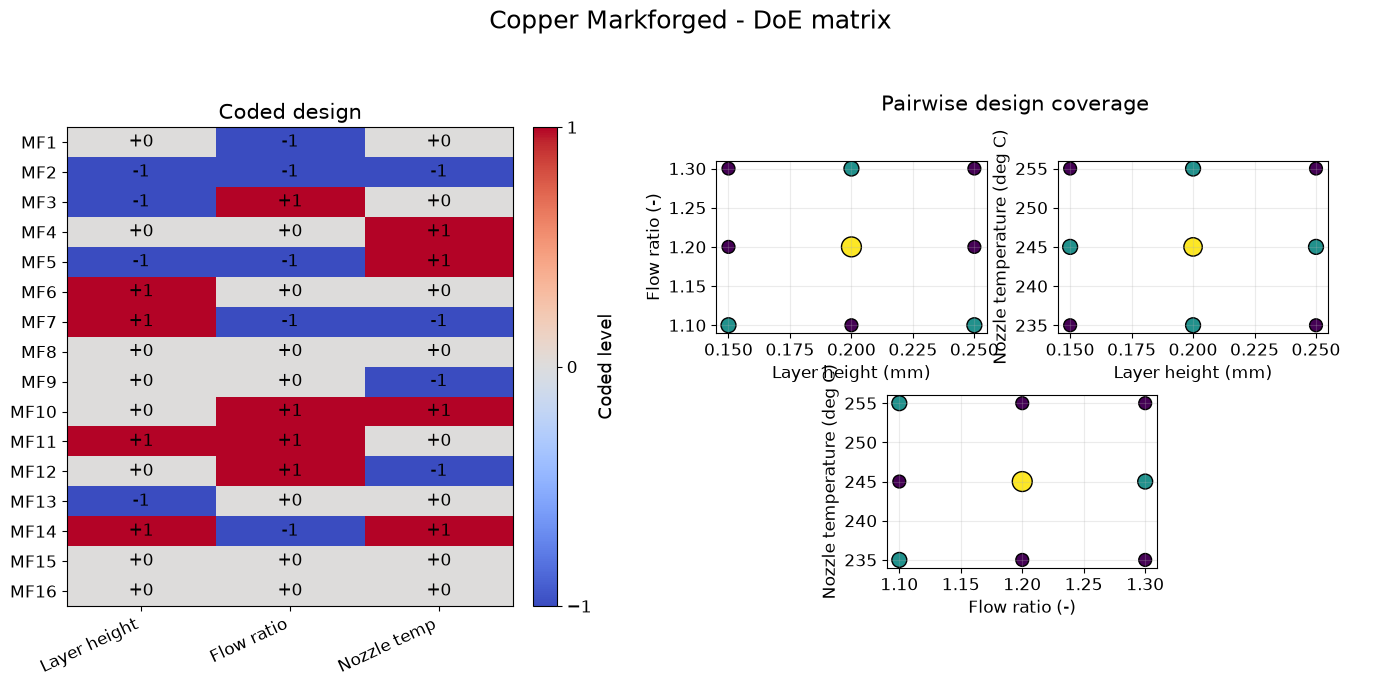

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1.0, 1.45]})
fig.suptitle("Copper Markforged - DoE matrix", fontsize=MARKFORGED_SUPTITLE_SIZE)

matrix = design_df[FACTOR_COLUMNS].to_numpy()
image = axes[0].imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
axes[0].set_title("Coded design")
axes[0].set_xticks(range(3), ["Layer height", "Flow ratio", "Nozzle temp"], rotation=25, ha="right")
axes[0].set_yticks(range(len(design_df)), design_df["Run"])
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        axes[0].text(column_index, row_index, f"{matrix[row_index, column_index]:+d}", ha="center", va="center", fontsize=MARKFORGED_TICK_SIZE)
colorbar = fig.colorbar(image, ax=axes[0], ticks=[-1, 0, 1], fraction=0.05, pad=0.04)
colorbar.set_label("Coded level")

pair_definitions = [
    ("layer_height_mm", "flow_ratio", "Layer height (mm)", "Flow ratio (-)"),
    ("layer_height_mm", "nozzle_temperature_C", "Layer height (mm)", "Nozzle temperature (deg C)"),
    ("flow_ratio", "nozzle_temperature_C", "Flow ratio (-)", "Nozzle temperature (deg C)"),
]
inset_positions = [(0.08, 0.57, 0.38, 0.36), (0.56, 0.57, 0.38, 0.36), (0.32, 0.08, 0.38, 0.36)]
axes[1].axis("off")
axes[1].set_title("Pairwise design coverage", pad=12)
for pair, position in zip(pair_definitions, inset_positions):
    x_column, y_column, x_label, y_label = pair
    inset = axes[1].inset_axes(position)
    grouped = design_df.groupby([x_column, y_column], as_index=False).size()
    inset.scatter(
        grouped[x_column], grouped[y_column],
        s=55 + 30 * grouped["size"], c=grouped["size"],
        cmap="viridis", vmin=1, vmax=3, edgecolor="black",
    )
    inset.set_xlabel(x_label, fontsize=MARKFORGED_TICK_SIZE)
    inset.set_ylabel(y_label, fontsize=MARKFORGED_TICK_SIZE)
    inset.tick_params(labelsize=MARKFORGED_TICK_SIZE)
    inset.grid(alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 6. Export matrix and measurements

In [6]:
matrix_path = MATRIX_OUTPUT_DIR / "copper_markforged_doe_matrix.csv"
measurement_path = MATRIX_OUTPUT_DIR / "copper_markforged_measurements.csv"
preliminary_path = MATRIX_OUTPUT_DIR / "copper_markforged_preliminary_tests.csv"
confirmation_path = MATRIX_OUTPUT_DIR / "copper_markforged_confirmation_runs.csv"
failed_path = MATRIX_OUTPUT_DIR / "copper_markforged_failed_attempts.csv"

design_df[["Run", *FACTOR_COLUMNS, "layer_height_mm", "flow_ratio", "nozzle_temperature_C"]].to_csv(matrix_path, index=False)
design_df[DISPLAY_COLUMNS].to_csv(measurement_path, index=False)
preliminary_tests_df.to_csv(preliminary_path, index=False)
confirmation_df.to_csv(confirmation_path, index=False)
failed_attempts_df.to_csv(failed_path, index=False)

print(f"Saved DoE matrix: {matrix_path.resolve()}")
print(f"Saved measurements: {measurement_path.resolve()}")
print(f"Saved preliminary tests: {preliminary_path.resolve()}")
print(f"Saved confirmation runs: {confirmation_path.resolve()}")
print(f"Saved excluded attempts: {failed_path.resolve()}")

Saved DoE matrix: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_Markforged\copper_markforged_doe_matrix.csv
Saved measurements: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_Markforged\copper_markforged_measurements.csv
Saved preliminary tests: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_Markforged\copper_markforged_preliminary_tests.csv
Saved confirmation runs: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_Markforged\copper_markforged_confirmation_runs.csv
Saved excluded attempts: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_Markforged\copper_markforged_failed_attempts.csv


# Mass Measurements

All sixteen mass responses are available. MF8, MF15, and MF16 are independently printed center-point specimens and provide two pure-error degrees of freedom. The correlation plot compares the precision-scale mass used for the DoE response with the separate mass-in-air reading recorded during the Archimedes measurement; those readings are not treated as print replicas.

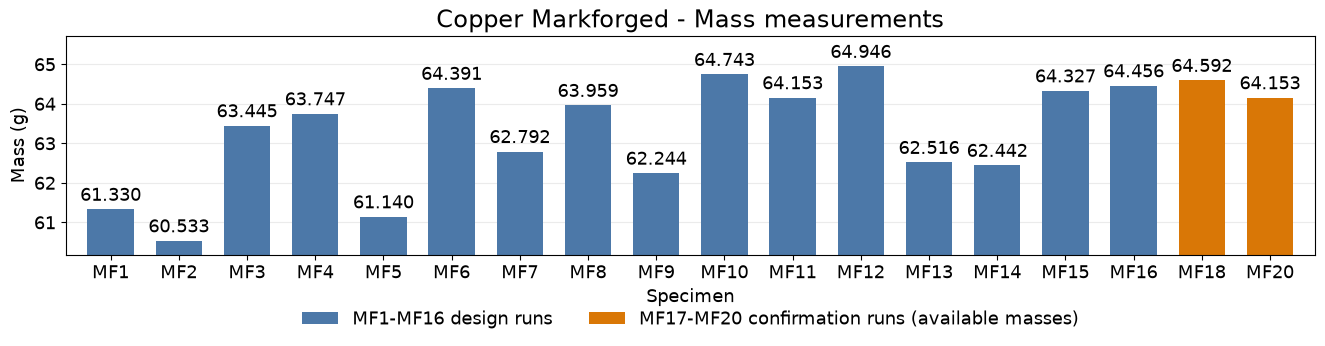

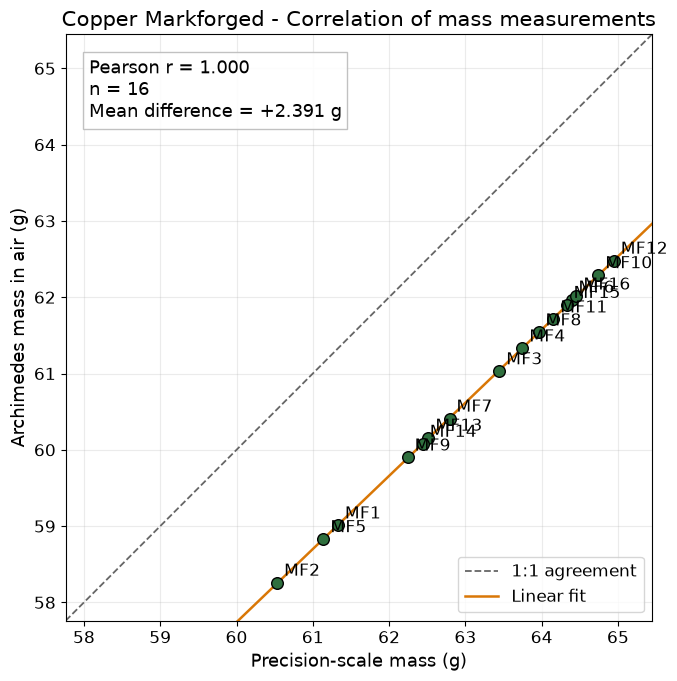

In [7]:
def plot_available_measurements(
    data, response, y_label, title, color, digits, y_max=None,
    highlight_runs=None, highlight_color="#d97706",
    base_label="Design runs", highlight_label="Confirmation runs",
    bar_width=0.68, value_fontsize=13, text_fontsize=13, title_fontsize=17,
    figure_width=None, title_pad=6, show_mean=False, label_padding=3,
    mean_line_color="#a8cfa3", mean_sd=None,
):
    plot_df = data.dropna(subset=[response]).copy()
    highlight_runs = set(highlight_runs or [])
    bar_colors = [highlight_color if run in highlight_runs else color for run in plot_df["Run"]]
    if figure_width is None:
        figure_width = max(10.5, 0.58 * len(plot_df) + (3.0 if highlight_runs else 0))
    fig, ax = plt.subplots(figsize=(figure_width, 4.4))
    bars = ax.bar(
        plot_df["Run"], plot_df[response], color=bar_colors,
        width=bar_width, zorder=2,
    )
    ax.bar_label(bars, fmt=f"%.{digits}f", padding=label_padding, fontsize=value_fontsize)
    mean_value = float(plot_df[response].mean()) if show_mean else None
    if show_mean:
        ax.axhline(
            mean_value, color=mean_line_color, linestyle="--",
            linewidth=1.6, zorder=1,
        )
    ax.set_xlabel("Specimen", fontsize=text_fontsize)
    ax.set_ylabel(y_label, fontsize=text_fontsize)
    ax.set_title(title, fontsize=title_fontsize, pad=title_pad)
    ax.tick_params(axis="both", labelsize=text_fontsize)
    ax.grid(axis="y", alpha=0.25)
    y_span = plot_df[response].max() - plot_df[response].min()
    padding = max(0.08 * y_span, 0.05)
    y_upper = y_max if y_max is not None else plot_df[response].max() + 2.2 * padding
    ax.set_ylim(plot_df[response].min() - padding, y_upper)
    edge_gap = 1.0 - bar_width
    ax.set_xlim(
        -bar_width / 2.0 - edge_gap,
        len(plot_df) - 1 + bar_width / 2.0 + edge_gap,
    )
    legend_handles = []
    if highlight_runs:
        from matplotlib.patches import Patch
        legend_handles.extend([
            Patch(facecolor=color, label=base_label),
            Patch(facecolor=highlight_color, label=highlight_label),
        ])
    if show_mean:
        from matplotlib.lines import Line2D
        legend_handles.append(
            Line2D(
                [0], [0], color=mean_line_color, linestyle="--",
                linewidth=1.6,
                label=(
                    f"Average density: {mean_value:.2f}"
                    + (f" \u00b1 {mean_sd:.3f}" if mean_sd is not None and np.isfinite(mean_sd) else "")
                    + " g/cm3"
                ),
            )
        )
    if legend_handles:
        ax.legend(
            handles=legend_handles, loc="upper center",
            bbox_to_anchor=(0.5, -0.18),
            ncol=len(legend_handles), frameon=False,
            fontsize=text_fontsize,
        )
        plt.tight_layout(rect=(0, 0.12, 1, 1))
    else:
        plt.tight_layout()
    plt.show()

mass_measurements_df = pd.concat([design_df, confirmation_df], ignore_index=True)

plot_available_measurements(
    mass_measurements_df,
    response="mass_g",
    y_label="Mass (g)",
    title="Copper Markforged - Mass measurements",
    color="#4c78a8",
    digits=3,
    highlight_runs={"MF17", "MF18", "MF19", "MF20"},
    highlight_color="#d97706",
    base_label="MF1-MF16 design runs",
    highlight_label="MF17-MF20 confirmation runs (available masses)",
)

mass_correlation_df = design_df.dropna(subset=["mass_g", "archimedes_mass_g"]).copy()
precision_mass = mass_correlation_df["mass_g"].to_numpy(dtype=float)
archimedes_mass = mass_correlation_df["archimedes_mass_g"].to_numpy(dtype=float)
pearson_r = float(np.corrcoef(precision_mass, archimedes_mass)[0, 1])
slope, intercept = np.polyfit(precision_mass, archimedes_mass, 1)
mean_difference = float(np.mean(precision_mass - archimedes_mass))
axis_min = min(precision_mass.min(), archimedes_mass.min()) - 0.5
axis_max = max(precision_mass.max(), archimedes_mass.max()) + 0.5
line_x = np.linspace(axis_min, axis_max, 100)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(precision_mass, archimedes_mass, s=70, color="#2f6f3e", edgecolor="black", zorder=3)
for _, row in mass_correlation_df.iterrows():
    ax.annotate(row["Run"], (row["mass_g"], row["archimedes_mass_g"]), xytext=(5, 5), textcoords="offset points", fontsize=MARKFORGED_TICK_SIZE)
ax.plot(line_x, line_x, linestyle="--", color="#666666", linewidth=1.3, label="1:1 agreement")
ax.plot(line_x, slope * line_x + intercept, color="#d97706", linewidth=1.8, label="Linear fit")
ax.text(
    0.04, 0.96,
    f"Pearson r = {pearson_r:.3f}\nn = {len(mass_correlation_df)}\nMean difference = {mean_difference:+.3f} g",
    transform=ax.transAxes, va="top",
    bbox={"facecolor": "white", "edgecolor": "#bbbbbb", "alpha": 0.9},
)
ax.set_xlim(axis_min, axis_max)
ax.set_ylim(axis_min, axis_max)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Precision-scale mass (g)")
ax.set_ylabel("Archimedes mass in air (g)")
ax.set_title("Copper Markforged - Correlation of mass measurements")
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Preliminary mass regression

,factor,coded_level,available_runs
0,A_layer_height,-1,4
1,A_layer_height,0,8
2,A_layer_height,1,4
3,B_flow_ratio,-1,5
4,B_flow_ratio,0,7
5,B_flow_ratio,1,4
6,C_nozzle_temp,-1,4
7,C_nozzle_temp,0,8
8,C_nozzle_temp,1,4


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,16,4,4,True,12,0.7647,0.7477


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,3,21.80567,7.26856,12.99988,0.00044
1,Residual,12,6.70950,0.55912,NaN,NaN
2,Total,15,28.51516,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value,p_value_below_0.1,pure_p_value_below_0.1
1,A_layer_height,0.76800,0.26437,2.90504,8.43925,0.01320,0.09118,8.42277,70.94311,0.01380,NaN,NaN,NaN,NaN,True,True
2,B_flow_ratio,1.37038,0.25012,5.47891,30.01842,0.00014,0.08627,15.88536,252.34482,0.00394,NaN,NaN,NaN,NaN,True,True
3,C_nozzle_temp,0.19462,0.26437,0.73619,0.54197,0.47576,0.09118,2.13448,4.55601,0.16637,NaN,NaN,NaN,NaN,False,False


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
6,A_layer_height=0|B_flow_ratio=0|C_nozzle_temp=0,3,64.24733,0.13302,2


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,1,3,0.13302,2,0.06651,0.2579


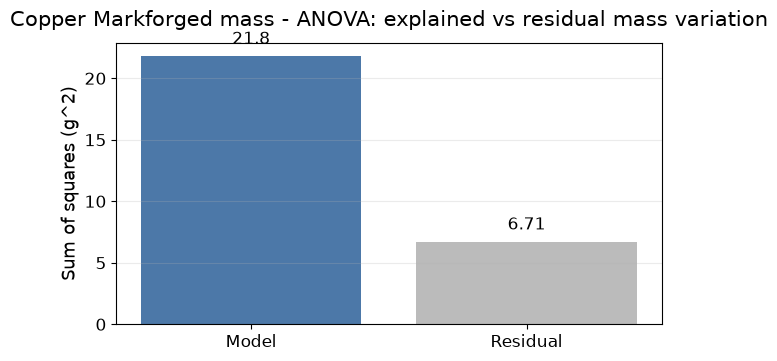

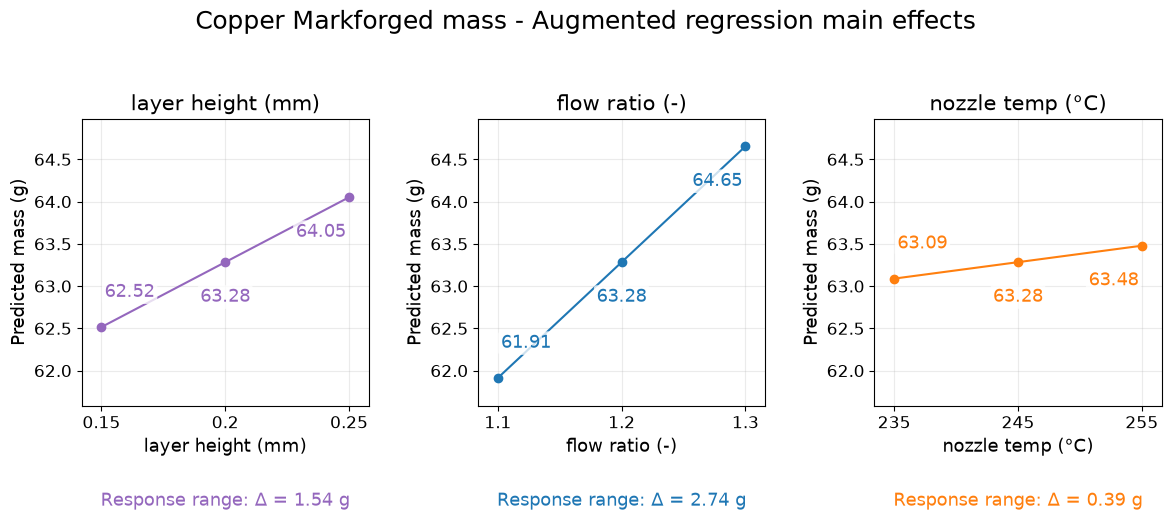

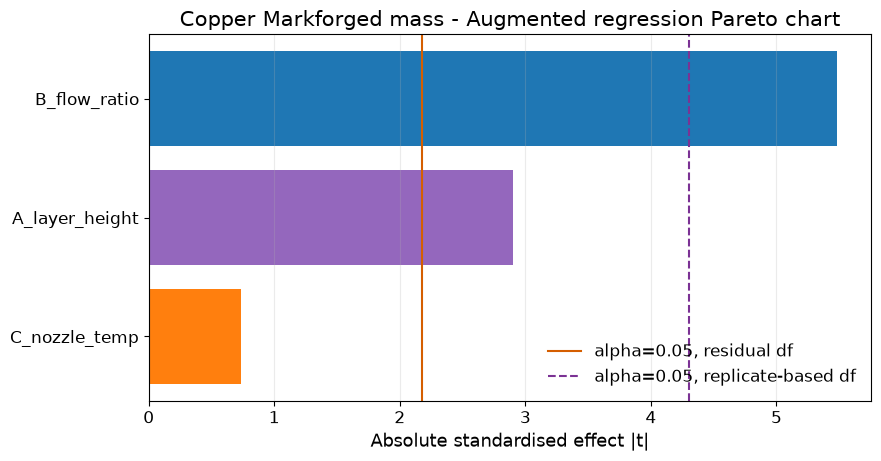

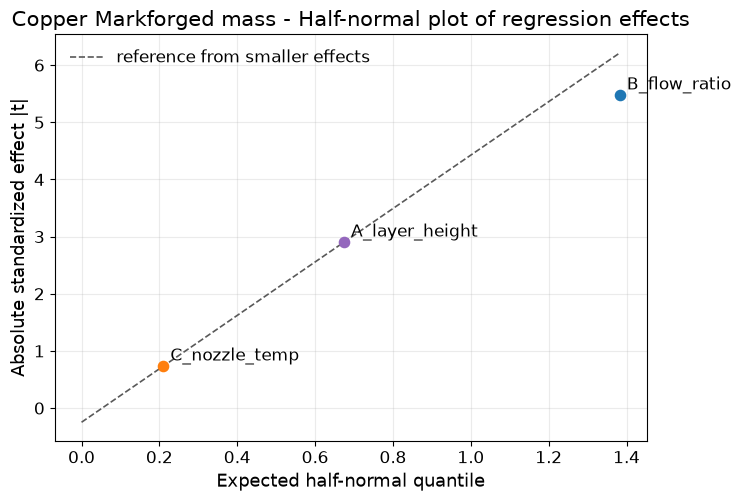

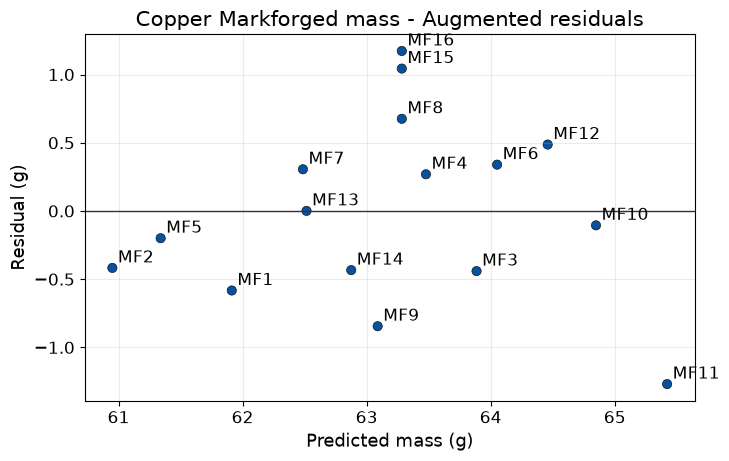

,measured_runs,model_terms,rank,residual_df,r_squared,residual_std
0,16,10,10,6,0.862,0.8099


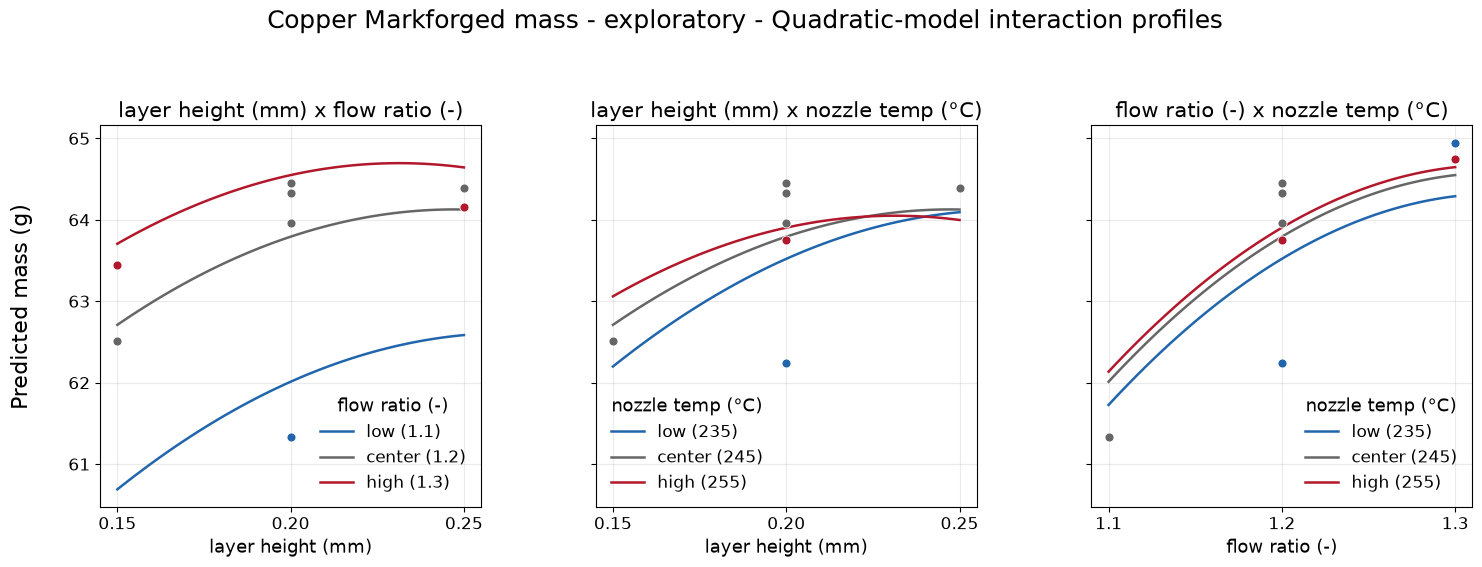

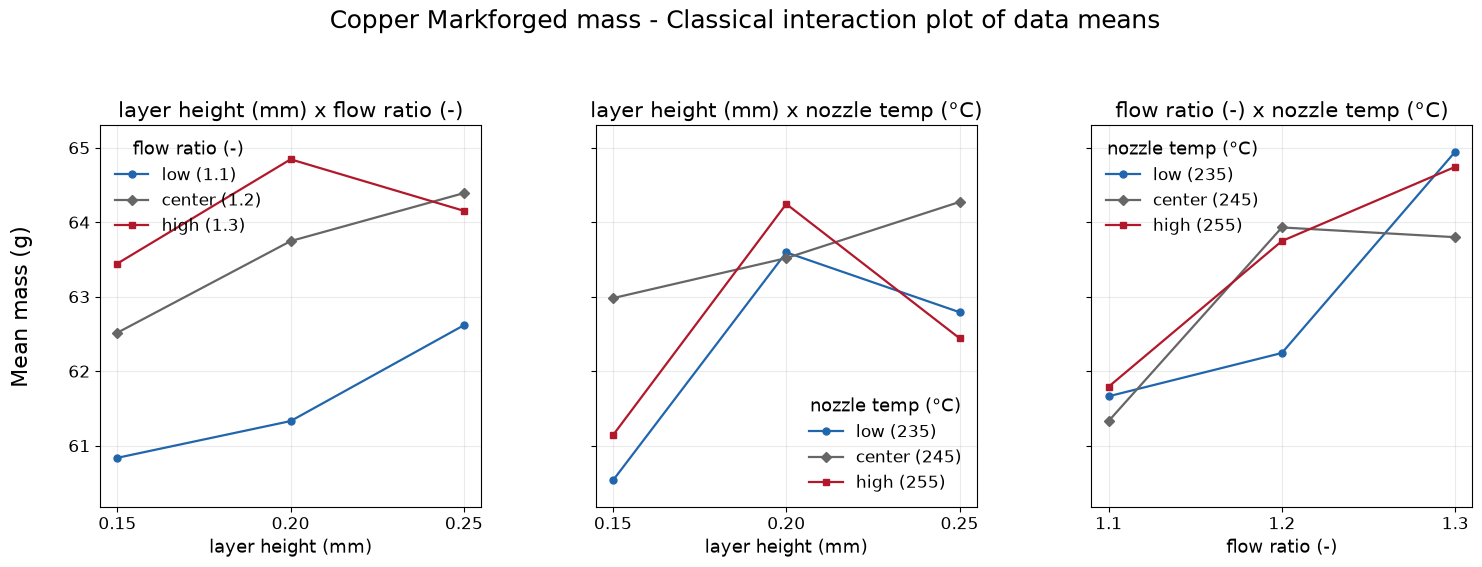

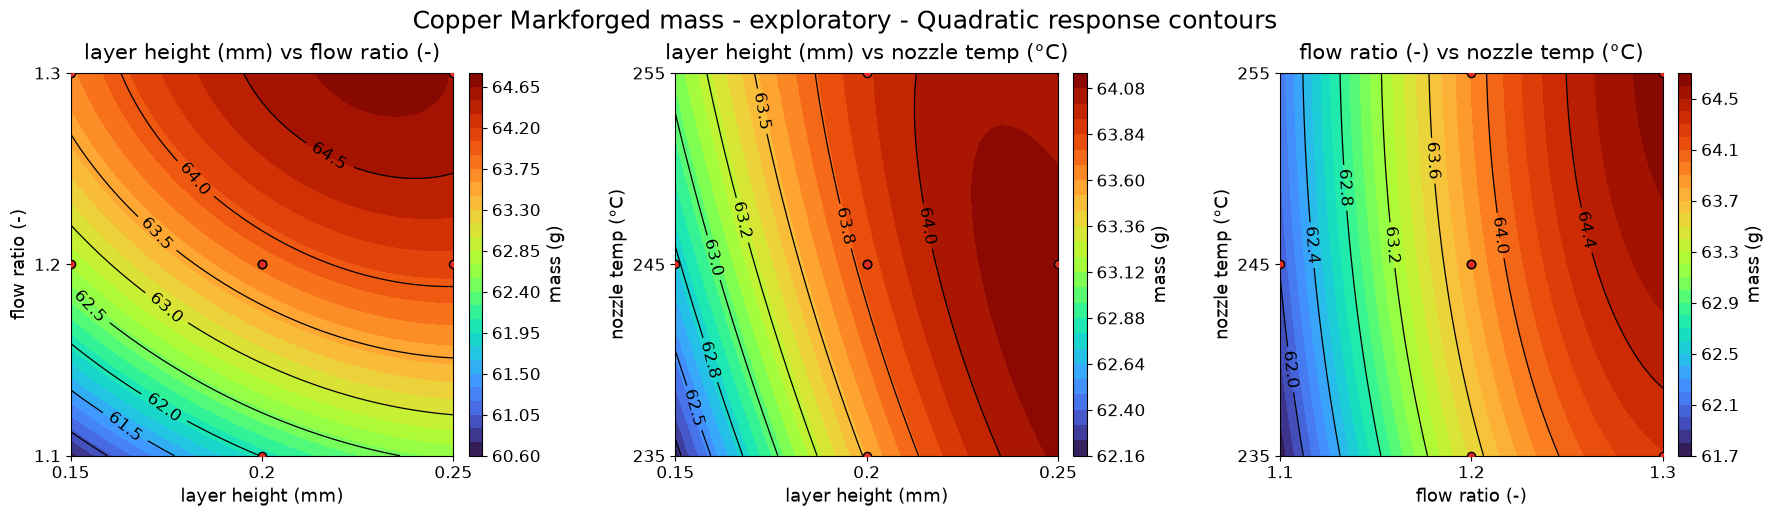

In [8]:
mass_model_df = design_df[["Run", *FACTOR_COLUMNS, "mass_g"]].copy()
mass_model = fit_main_effect_screening_model(
    mass_model_df,
    response="mass_g",
    factor_cols=FACTOR_COLUMNS,
)
mass_replicates, mass_pure_error_groups, mass_pure_error_summary = calculate_pure_error_from_replicates(
    mass_model_df,
    response="mass_g",
    factor_cols=FACTOR_COLUMNS,
)
mass_anova = build_model_anova_table(mass_model)
mass_coefficients = build_term_significance_table(
    mass_model,
    pure_error_summary=mass_pure_error_summary,
    additional_alphas=[0.10],
    additional_pure_error_alphas=[0.10],
)

display(build_factor_level_coverage(mass_model_df, response="mass_g", factor_cols=FACTOR_COLUMNS))
display(mass_model["info_df"].round(4))
display(mass_anova.round(5))
display(mass_coefficients.round(5))
display(mass_pure_error_groups.round(5))
display(mass_pure_error_summary.round(5))

if int(mass_pure_error_summary.loc[0, "df_pure"]) == 0:
    print("Replicate-based mass uncertainty is not available yet: only MF8 has a center-point mass result; MF15 or MF16 is still required.")

plot_model_anova(mass_anova, response="mass_g", experiment="Copper Markforged mass")
plot_augmented_main_effects(
    mass_model, LEVELS, experiment="Copper Markforged mass",
    figsize=(12, 5.8), square_axes=True,
)
plot_augmented_model_pareto(
    mass_model,
    experiment="Copper Markforged mass",
    alpha=SIGNIFICANCE_ALPHA,
    pure_error_summary=mass_pure_error_summary,
)
plot_screening_half_normal(mass_model, experiment="Copper Markforged mass")
plot_augmented_residuals(mass_model, confirmation_run="", experiment="Copper Markforged mass")

mass_interaction_model = fit_quadratic_response_surface(
    mass_model_df,
    response="mass_g",
    factor_cols=FACTOR_COLUMNS,
)
display(mass_interaction_model["info_df"].round(4))
plot_quadratic_interaction_profiles(
    mass_interaction_model,
    LEVELS,
    experiment="Copper Markforged mass - exploratory",
    figsize=(15, 6.2), square_axes=True,
)
plot_three_level_interaction_means(
    mass_model_df,
    response="mass_g",
    factor_cols=FACTOR_COLUMNS,
    levels=LEVELS,
    experiment="Copper Markforged mass",
    figsize=(15, 6.2), square_axes=True,
)
plot_quadratic_surface_and_contour_pairs(
    mass_interaction_model,
    levels=LEVELS,
    fixed_level=0,
    experiment="Copper Markforged mass - exploratory",
    combine_pairs=True,
    contours_only=True,
    font_size=16,
    shared_colorbar=True,
)

# Density Measurements

Density in `g/cm3` is modeled directly. Relative density percentage is not fitted as a second response because it is a rescaling of density by the reference density and contains the same statistical information.

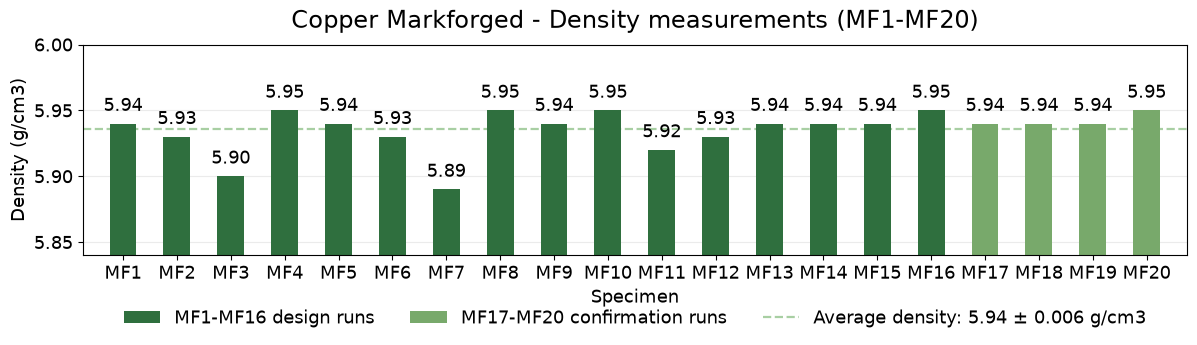

In [9]:
density_measurements_df = pd.concat([design_df, confirmation_df], ignore_index=True)
density_repeatability_by_setting = (
    density_measurements_df.dropna(subset=["density_g_cm3"])
    .groupby(["layer_height_mm", "flow_ratio", "nozzle_temperature_C"])["density_g_cm3"]
    .agg(["count", "std"])
)
markforged_average_density_sd = float(
    density_repeatability_by_setting.loc[
        density_repeatability_by_setting["count"] >= 2, "std"
    ].mean()
)

plot_available_measurements(
    density_measurements_df,
    response="density_g_cm3",
    y_label="Density (g/cm3)",
    title="Copper Markforged - Density measurements (MF1-MF20)",
    color="#2f6f3e",
    digits=2,
    y_max=6.00,
    highlight_runs={"MF17", "MF18", "MF19", "MF20"},
    highlight_color="#78a96b",
    base_label="MF1-MF16 design runs",
    highlight_label="MF17-MF20 confirmation runs",
    bar_width=0.50,
    value_fontsize=13,
    text_fontsize=13,
    title_fontsize=17,
    figure_width=12.5,
    title_pad=12,
    show_mean=True,
    mean_line_color="#a8cfa3",
    mean_sd=markforged_average_density_sd,
    label_padding=6,
)

## 8. Complete density regression

,factor,coded_level,available_runs
0,A_layer_height,-1,4
1,A_layer_height,0,8
2,A_layer_height,1,4
3,B_flow_ratio,-1,5
4,B_flow_ratio,0,7
5,B_flow_ratio,1,4
6,C_nozzle_temp,-1,4
7,C_nozzle_temp,0,8
8,C_nozzle_temp,1,4


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,16,4,4,True,12,0.2469,0.0169


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,3,0.001129,0.000376,1.311076,0.316162
1,Residual,12,0.003446,0.000287,NaN,NaN
2,Total,15,0.004575,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value,p_value_below_0.1,pure_p_value_below_0.1
1,A_layer_height,-0.003750,0.005991,-0.625940,0.391801,0.543077,0.002041,-1.837117,3.375000,0.207594,NaN,NaN,NaN,NaN,False,False
2,B_flow_ratio,-0.000699,0.005668,-0.123375,0.015221,0.903852,0.001931,-0.362103,0.131119,0.751956,NaN,NaN,NaN,NaN,False,False
3,C_nozzle_temp,0.011250,0.005991,1.877820,3.526206,0.084916,0.002041,5.511352,30.375000,0.031380,NaN,NaN,NaN,NaN,True,True


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
6,A_layer_height=0|B_flow_ratio=0|C_nozzle_temp=0,3,5.946667,0.000067,2


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,1,3,0.000067,2,0.000033,0.005774


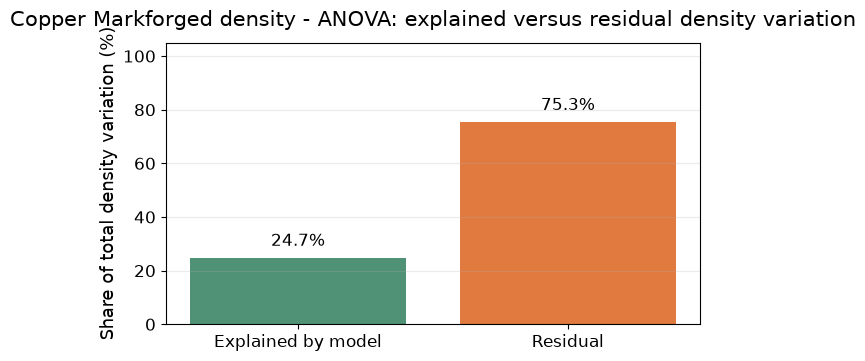

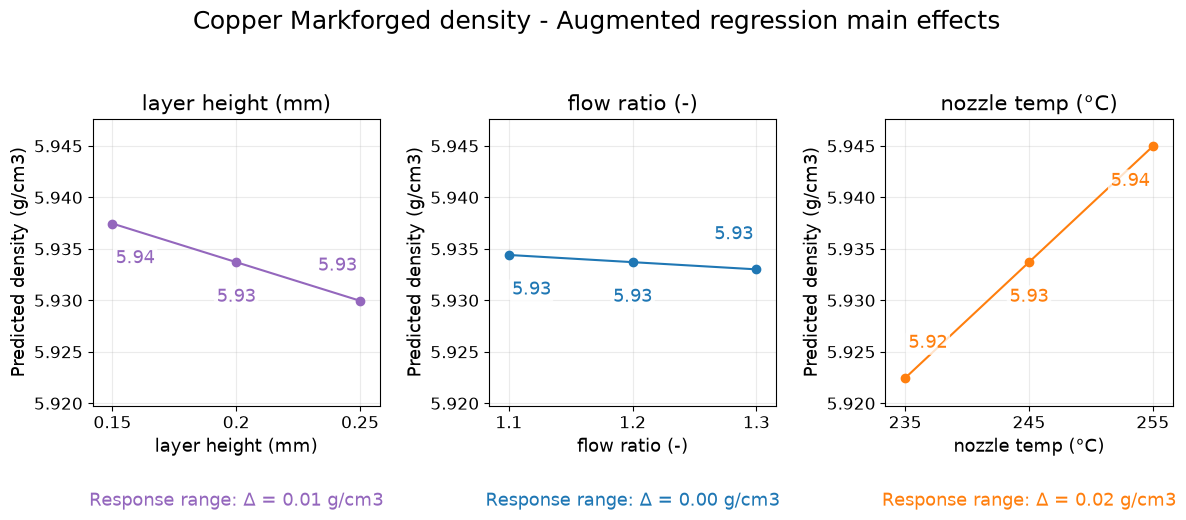

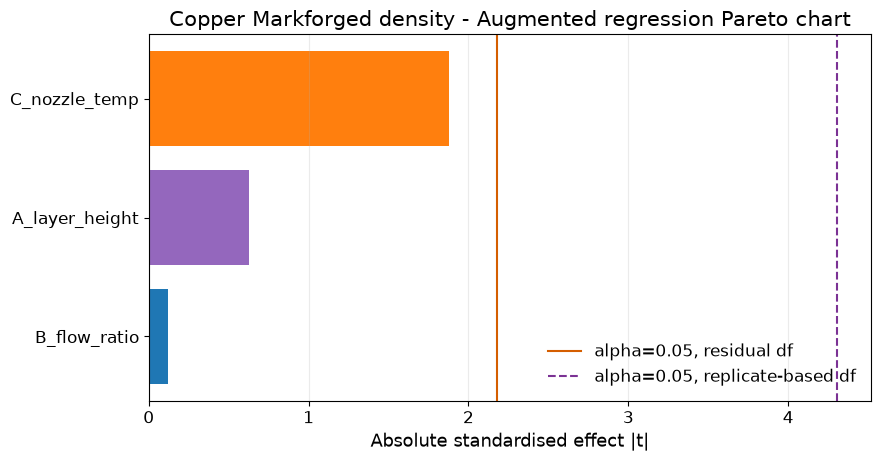

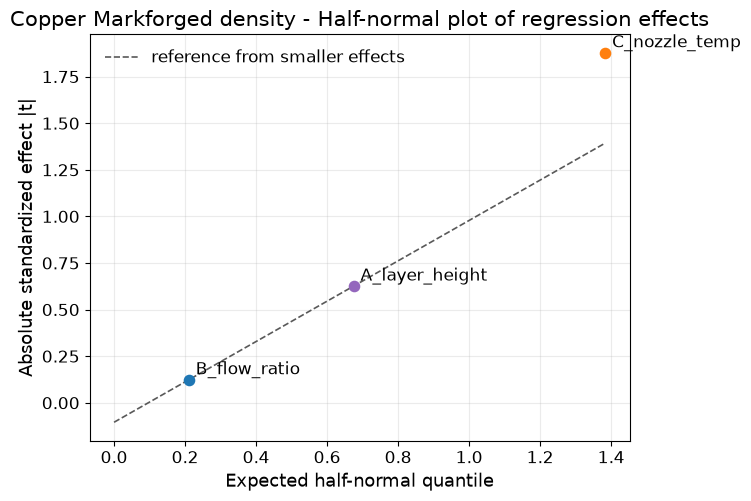

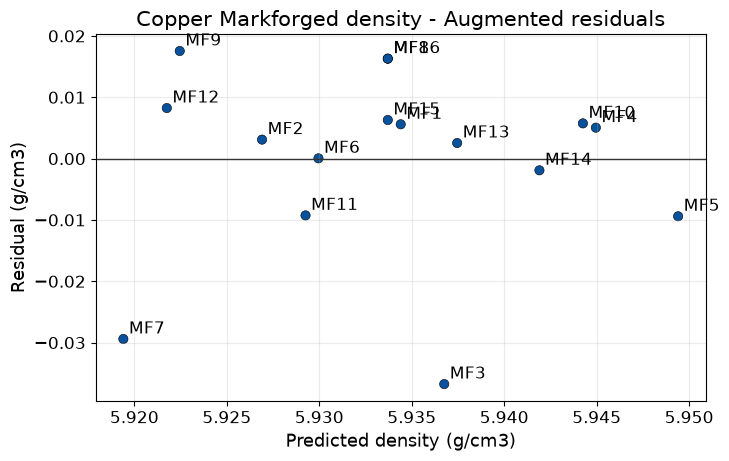

,measured_runs,model_terms,rank,residual_df,r_squared,residual_std
0,16,10,10,6,0.9157,0.008


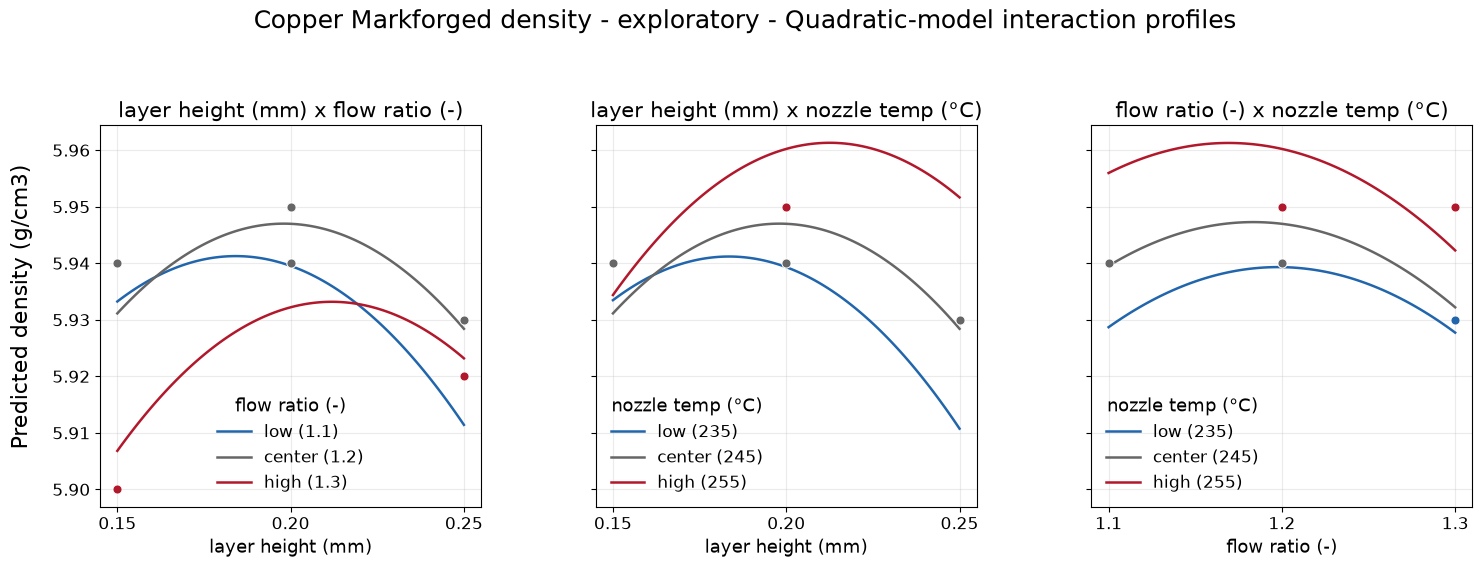

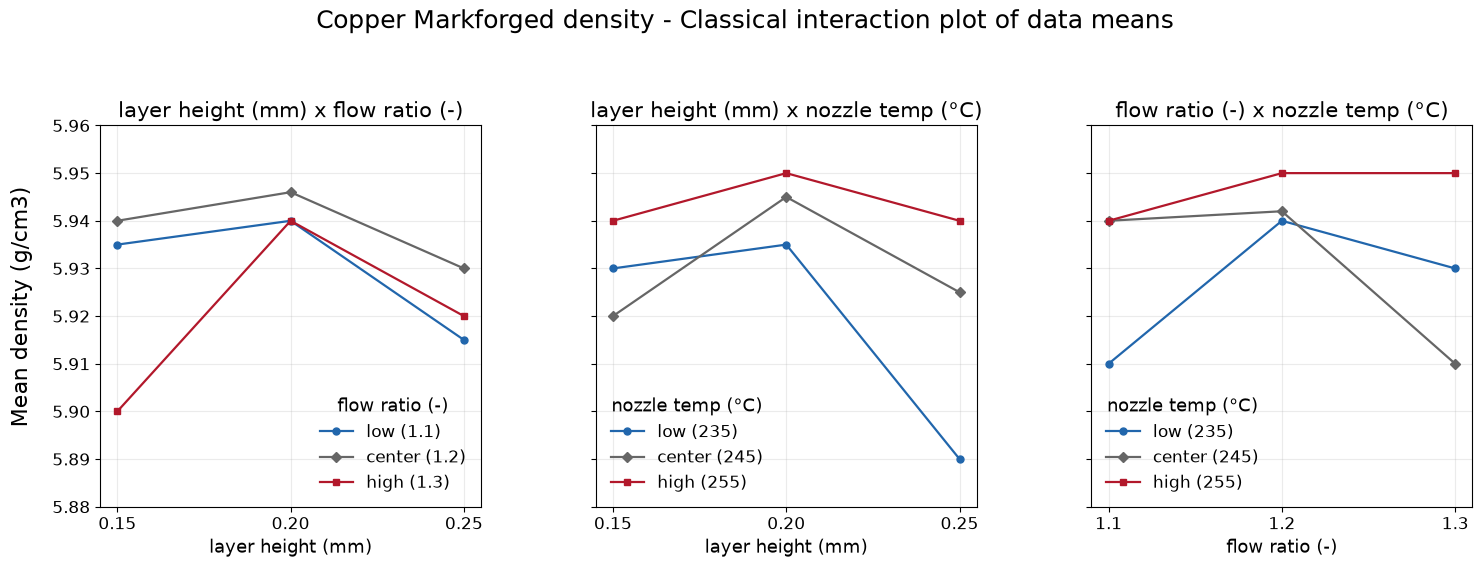

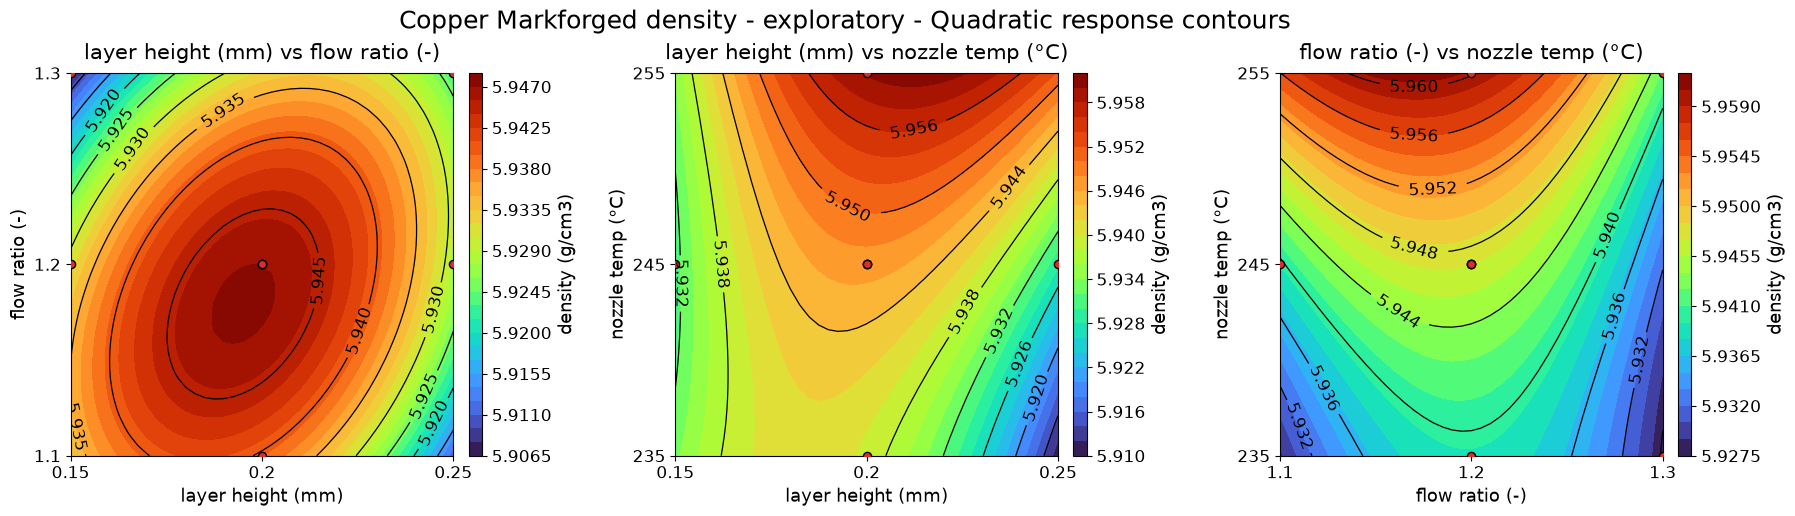

In [10]:
density_model_df = design_df[["Run", *FACTOR_COLUMNS, "density_g_cm3"]].copy()
density_model = fit_main_effect_screening_model(
    density_model_df,
    response="density_g_cm3",
    factor_cols=FACTOR_COLUMNS,
)
density_replicates, density_pure_error_groups, density_pure_error_summary = calculate_pure_error_from_replicates(
    density_model_df,
    response="density_g_cm3",
    factor_cols=FACTOR_COLUMNS,
)
density_anova = build_model_anova_table(density_model)
density_coefficients = build_term_significance_table(
    density_model,
    pure_error_summary=density_pure_error_summary,
    additional_alphas=[0.10],
    additional_pure_error_alphas=[0.10],
)

display(build_factor_level_coverage(density_model_df, response="density_g_cm3", factor_cols=FACTOR_COLUMNS))
display(density_model["info_df"].round(4))
display(density_anova.round(6))
display(density_coefficients.round(6))
display(density_pure_error_groups.round(6))
display(density_pure_error_summary.round(6))

if int(density_pure_error_summary.loc[0, "df_pure"]) == 0:
    print("Replicate-based density uncertainty is not available yet: only MF8 has a center-point density result; MF15 or MF16 is still required.")

plot_model_anova(
    density_anova,
    response="density_g_cm3",
    experiment="Copper Markforged density",
    variation_percent=True,
)
plot_augmented_main_effects(
    density_model, LEVELS, experiment="Copper Markforged density",
    figsize=(12, 5.8), square_axes=True,
)
plot_augmented_model_pareto(
    density_model,
    experiment="Copper Markforged density",
    alpha=SIGNIFICANCE_ALPHA,
    pure_error_summary=density_pure_error_summary,
)
plot_screening_half_normal(density_model, experiment="Copper Markforged density")
plot_augmented_residuals(density_model, confirmation_run="", experiment="Copper Markforged density")

density_interaction_model = fit_quadratic_response_surface(
    density_model_df,
    response="density_g_cm3",
    factor_cols=FACTOR_COLUMNS,
)
display(density_interaction_model["info_df"].round(4))
plot_quadratic_interaction_profiles(
    density_interaction_model,
    LEVELS,
    experiment="Copper Markforged density - exploratory",
    figsize=(15, 6.2), square_axes=True,
)
plot_three_level_interaction_means(
    density_model_df,
    response="density_g_cm3",
    factor_cols=FACTOR_COLUMNS,
    levels=LEVELS,
    experiment="Copper Markforged density",
    figsize=(15, 6.2), square_axes=True,
)
plot_quadratic_surface_and_contour_pairs(
    density_interaction_model,
    levels=LEVELS,
    fixed_level=0,
    experiment="Copper Markforged density - exploratory",
    combine_pairs=True,
    contours_only=True,
    font_size=16,
    shared_colorbar=True,
)

## 9. MF1-MF20 augmented sensitivity refits

These plots refit the models after appending every available MF17-MF20 response. Mass is shown first and density second. Missing values are excluded response-by-response: precision mass uses 18 measured runs, while density uses all MF1-MF20 runs ($n=20$). The original MF1-MF16 models above remain unchanged as the pre-confirmation reference.


,Run,A_layer_height,B_flow_ratio,C_nozzle_temp,mass_g,density_g_cm3
0,MF1,0.0,-1.0,0.0,61.330,5.94
1,MF2,-1.0,-1.0,-1.0,60.533,5.93
2,MF3,-1.0,1.0,0.0,63.445,5.90
3,MF4,0.0,0.0,1.0,63.747,5.95
4,MF5,-1.0,-1.0,1.0,61.140,5.94
5,MF6,1.0,0.0,0.0,64.391,5.93
6,MF7,1.0,-1.0,-1.0,62.792,5.89
7,MF8,0.0,0.0,0.0,63.959,5.95
8,MF9,0.0,0.0,-1.0,62.244,5.94
9,MF10,0.0,1.0,1.0,64.743,5.95


mass: 18 measured runs included


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,18,4,4,True,14,0.718158,0.790814


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,3,22.309511,7.436504,11.891051,0.000385
1,Residual,14,8.755412,0.625387,NaN,NaN
2,Total,17,31.064924,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value,p_value_below_0.1,pure_p_value_below_0.1
1,A_layer_height,0.783106,0.279007,2.806757,7.877887,0.013993,0.096001,8.157272,66.541093,0.003853,NaN,NaN,NaN,NaN,True,True
2,B_flow_ratio,1.369446,0.264223,5.182923,26.862693,0.000139,0.090914,15.063118,226.897517,0.000635,NaN,NaN,NaN,NaN,True,True
3,C_nozzle_temp,0.270156,0.264517,1.021319,1.043093,0.324429,0.091015,2.968257,8.810550,0.059151,NaN,NaN,NaN,NaN,False,True


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
6,A_layer_height=0.0|B_flow_ratio=0.0|C_nozzle_t...,4,64.3335,0.222121,3


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,1,4,0.222121,3,0.07404,0.272104


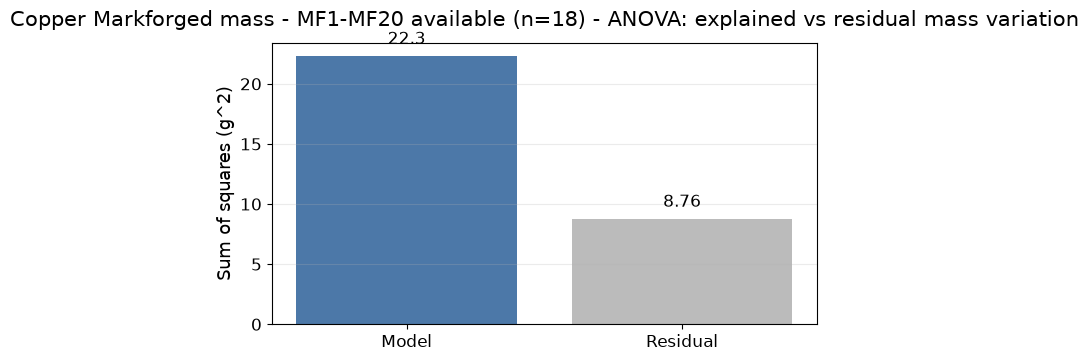

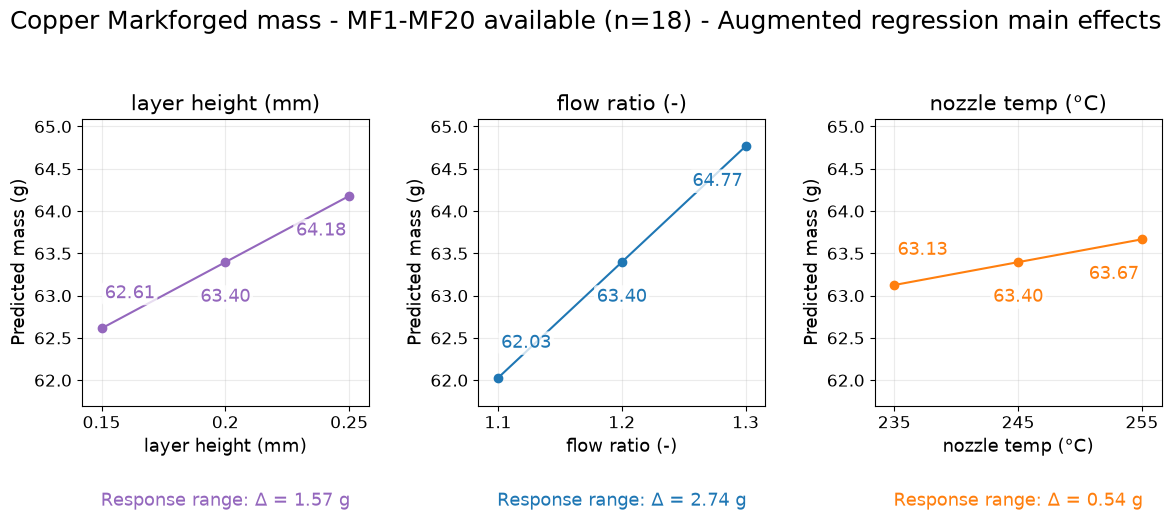

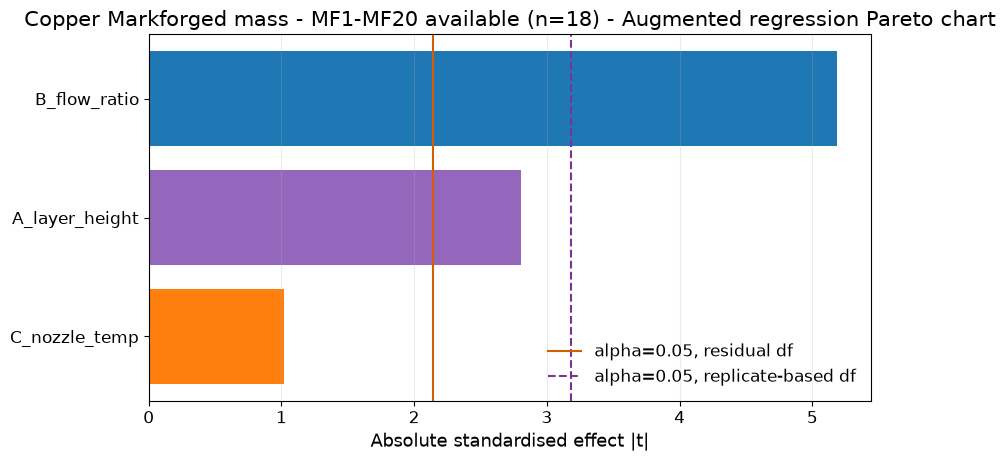

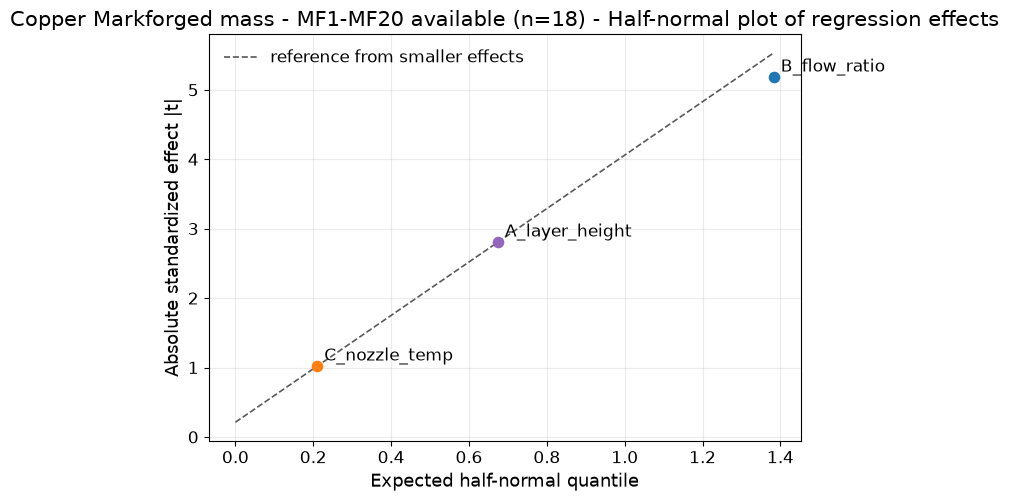

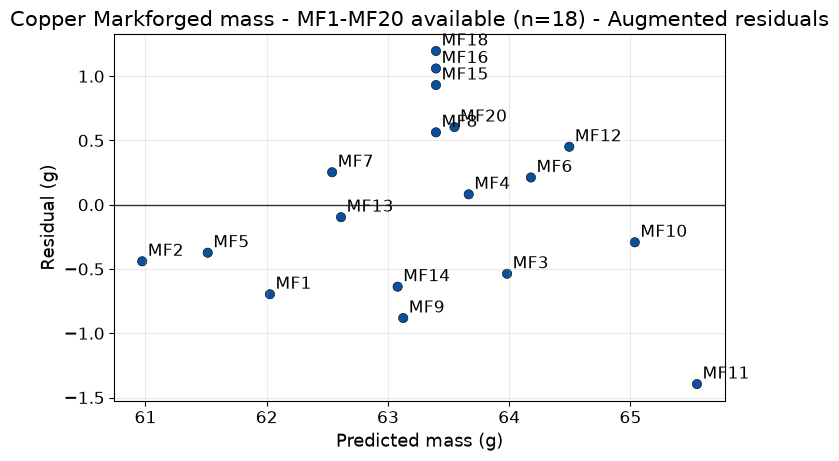

,measured_runs,model_terms,rank,residual_df,r_squared,residual_std
0,18,10,10,8,0.853182,0.755057


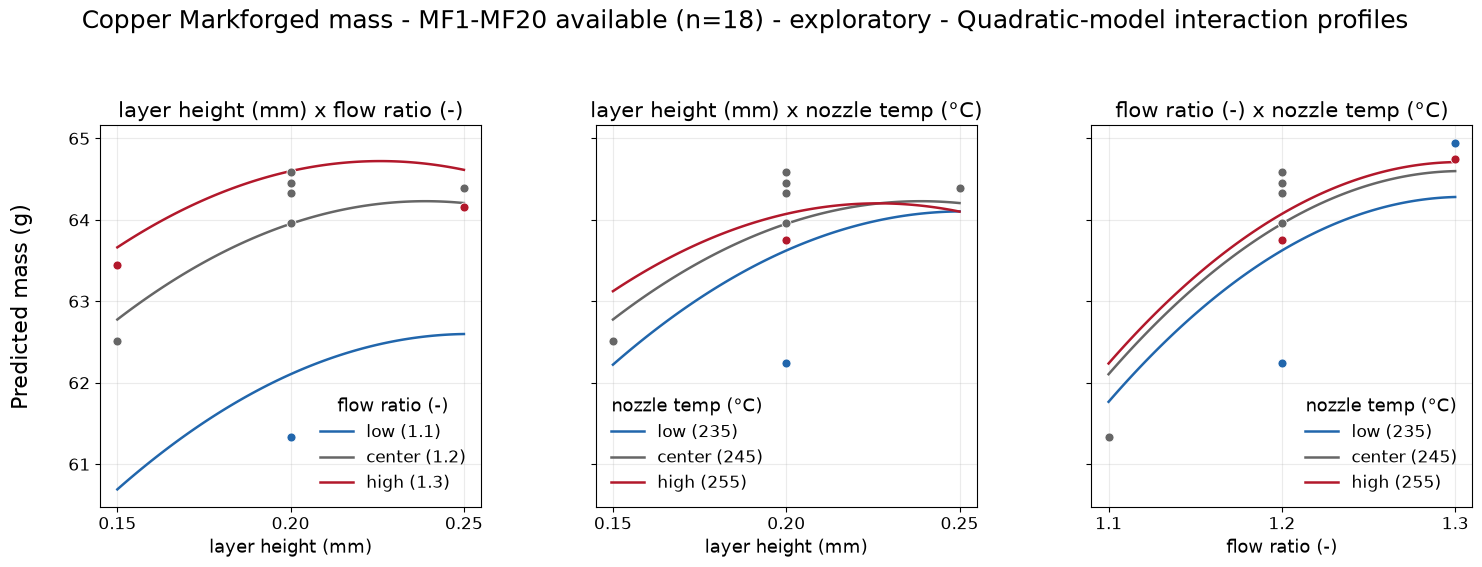

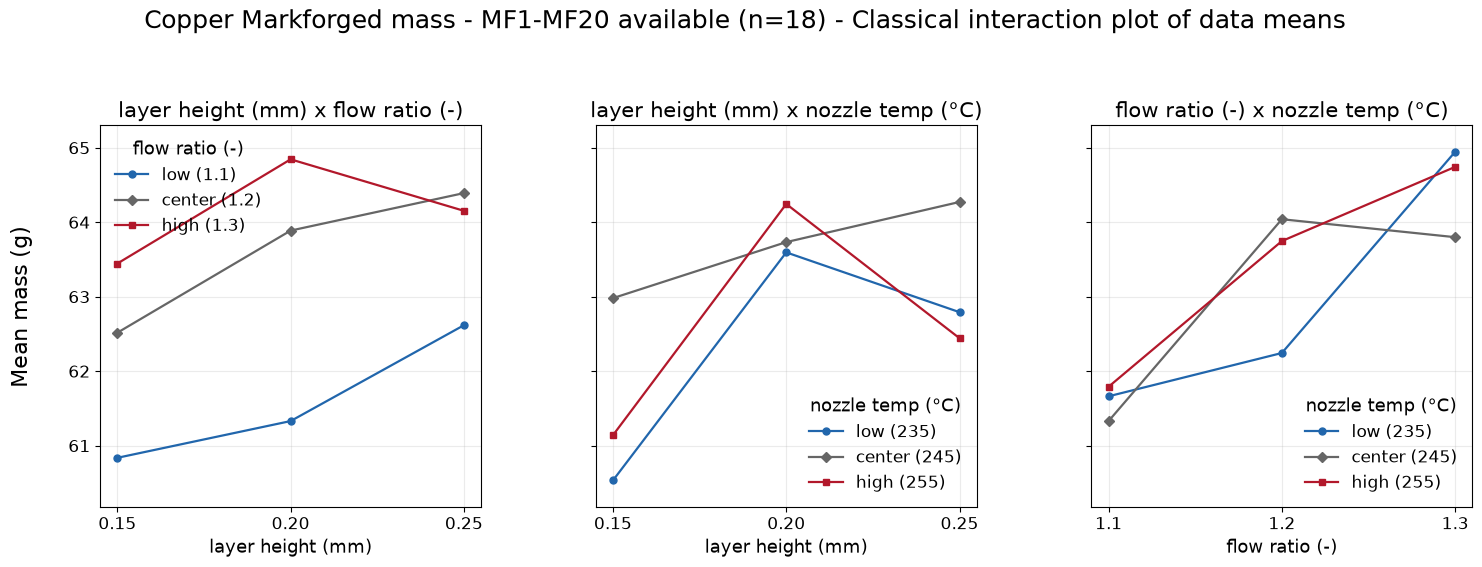

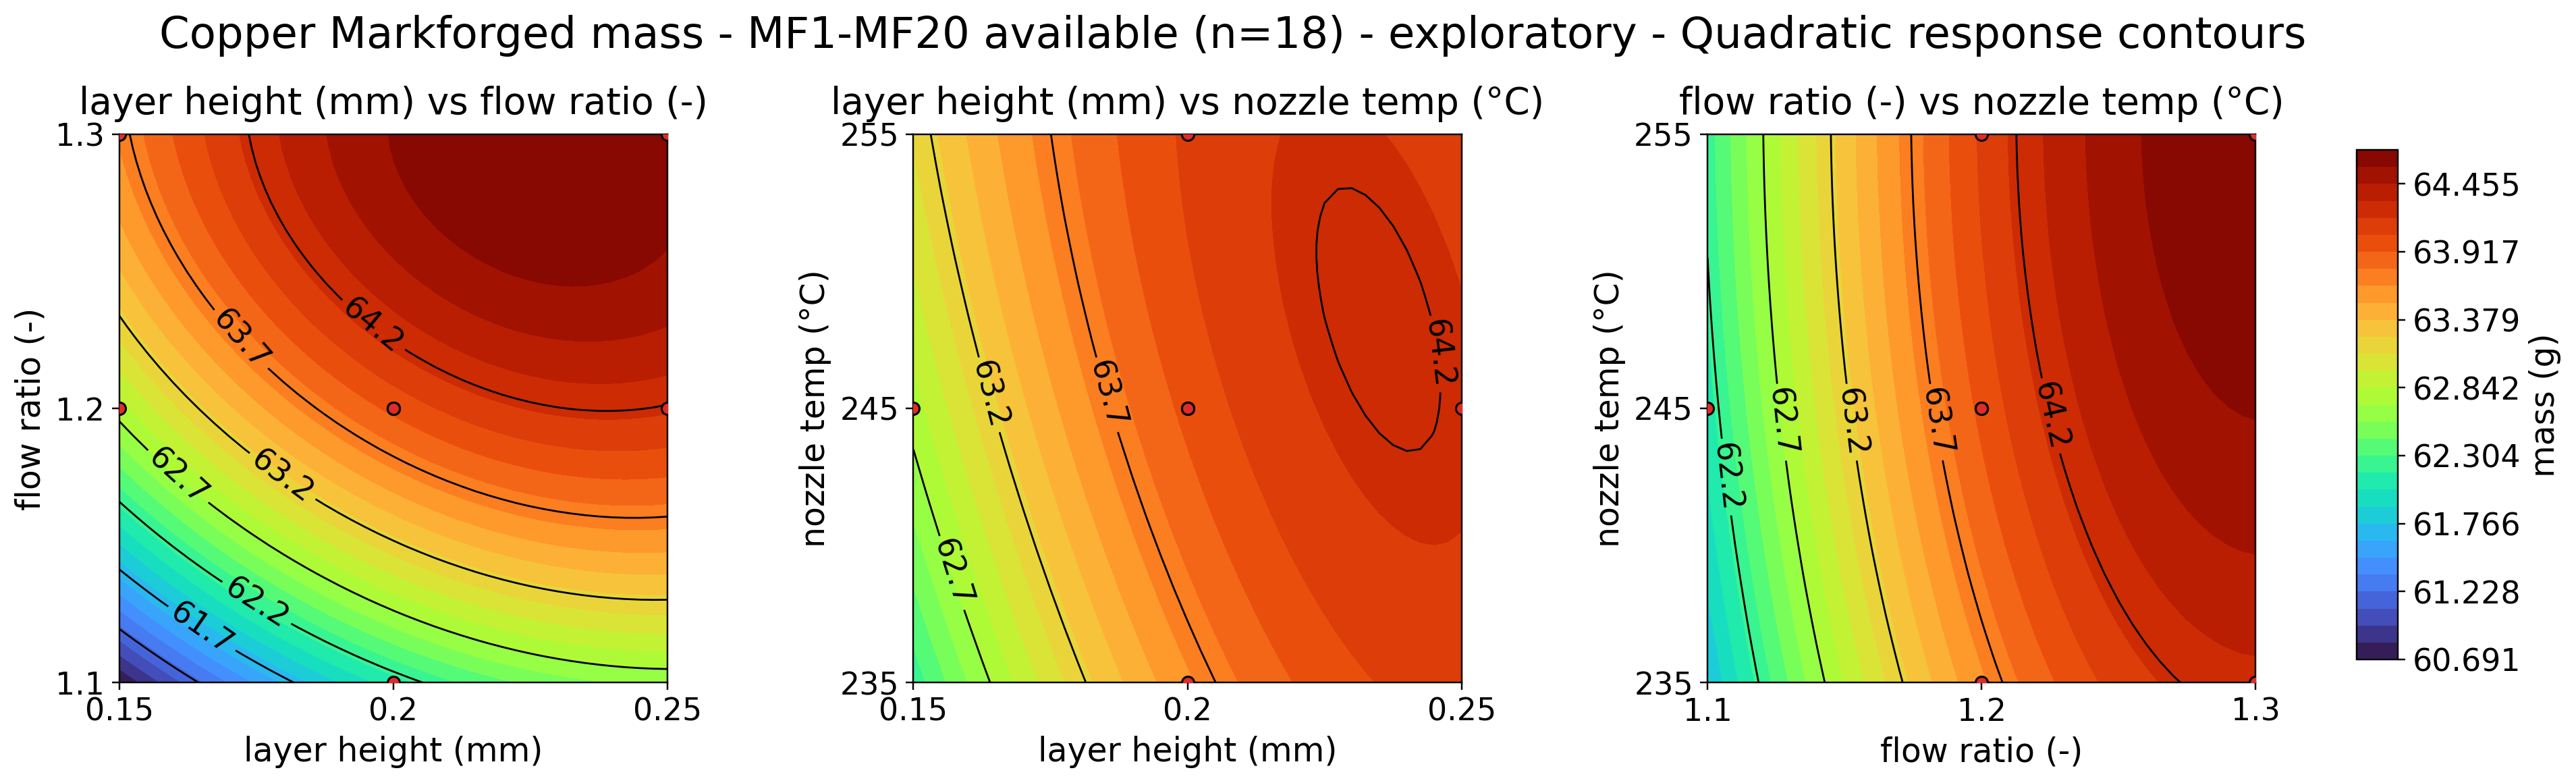

density: 20 measured runs included


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,20,4,4,True,16,0.274121,0.014902


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,3,0.001342,0.000447,2.014079,0.152547
1,Residual,16,0.003553,0.000222,NaN,NaN
2,Total,19,0.004895,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value,p_value_below_0.1,pure_p_value_below_0.1
1,A_layer_height,-0.003816,0.005244,-0.727690,0.529532,0.477318,0.002031,-1.878259,3.527856,0.119143,NaN,NaN,NaN,NaN,False,False
2,B_flow_ratio,-0.000616,0.004973,-0.123953,0.015364,0.902897,0.001927,-0.319937,0.102360,0.761953,NaN,NaN,NaN,NaN,False,False
3,C_nozzle_temp,0.010922,0.004598,2.375289,5.641996,0.030375,0.001781,6.130918,37.588156,0.001676,NaN,NaN,NaN,NaN,True,True


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
6,A_layer_height=0.0|B_flow_ratio=0.0|C_nozzle_t...,4,5.945000,0.000100,3
10,A_layer_height=0.19999999999999968|B_flow_rati...,3,5.943333,0.000067,2


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,2,7,0.000167,5,0.000033,0.005774


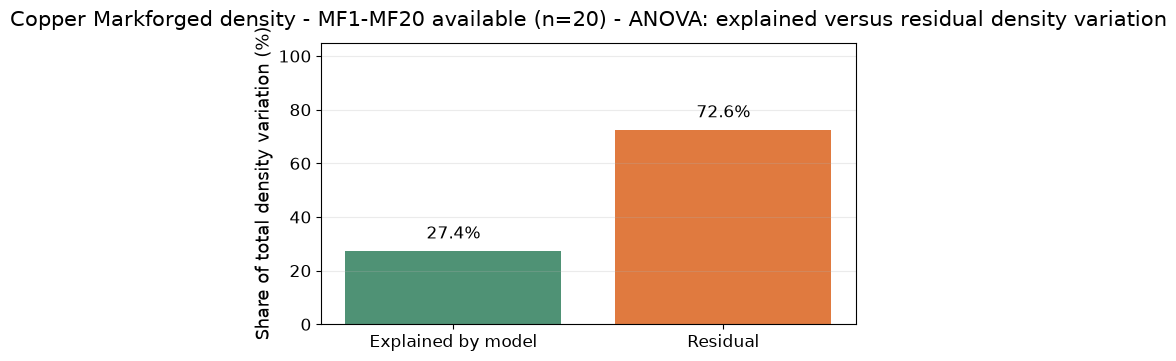

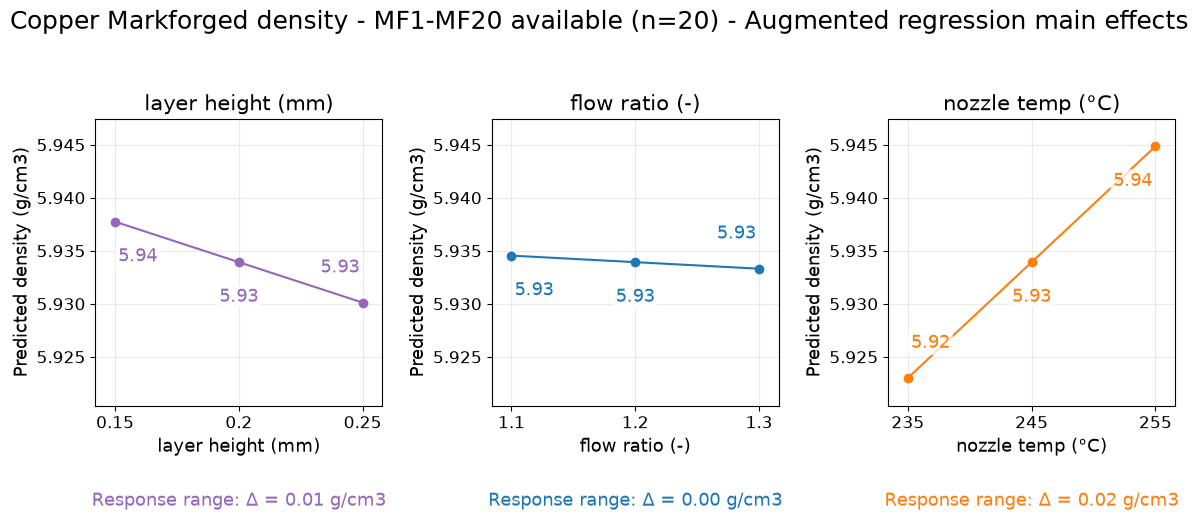

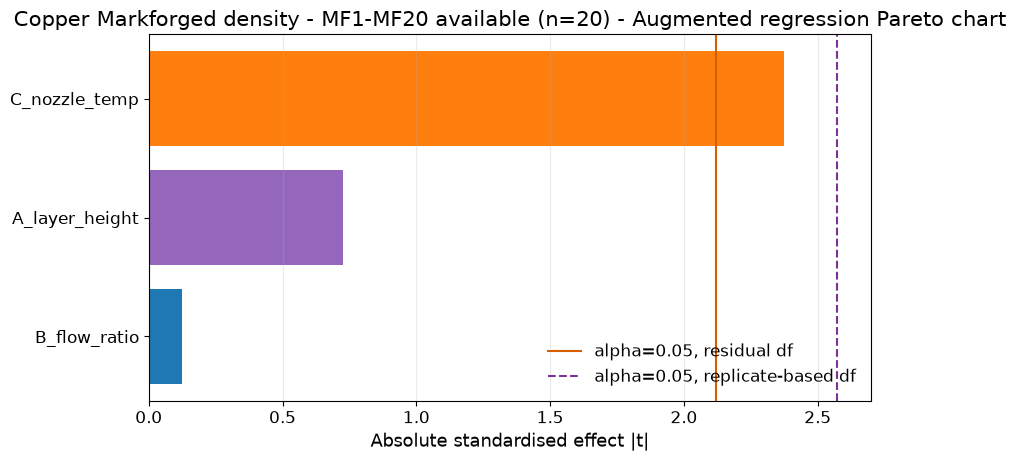

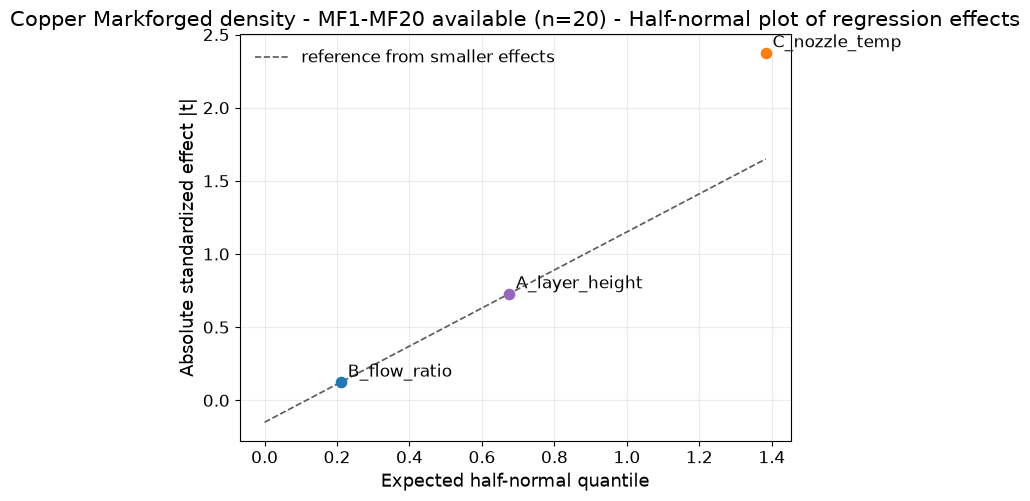

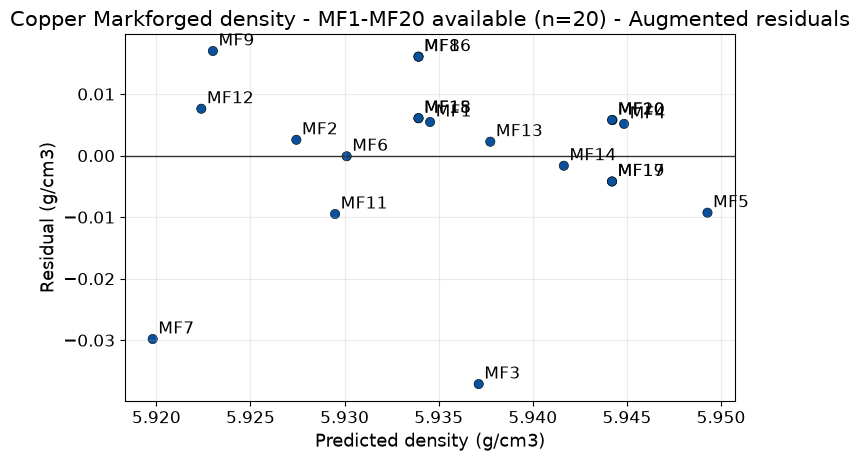

,measured_runs,model_terms,rank,residual_df,r_squared,residual_std
0,20,10,10,10,0.811455,0.009607


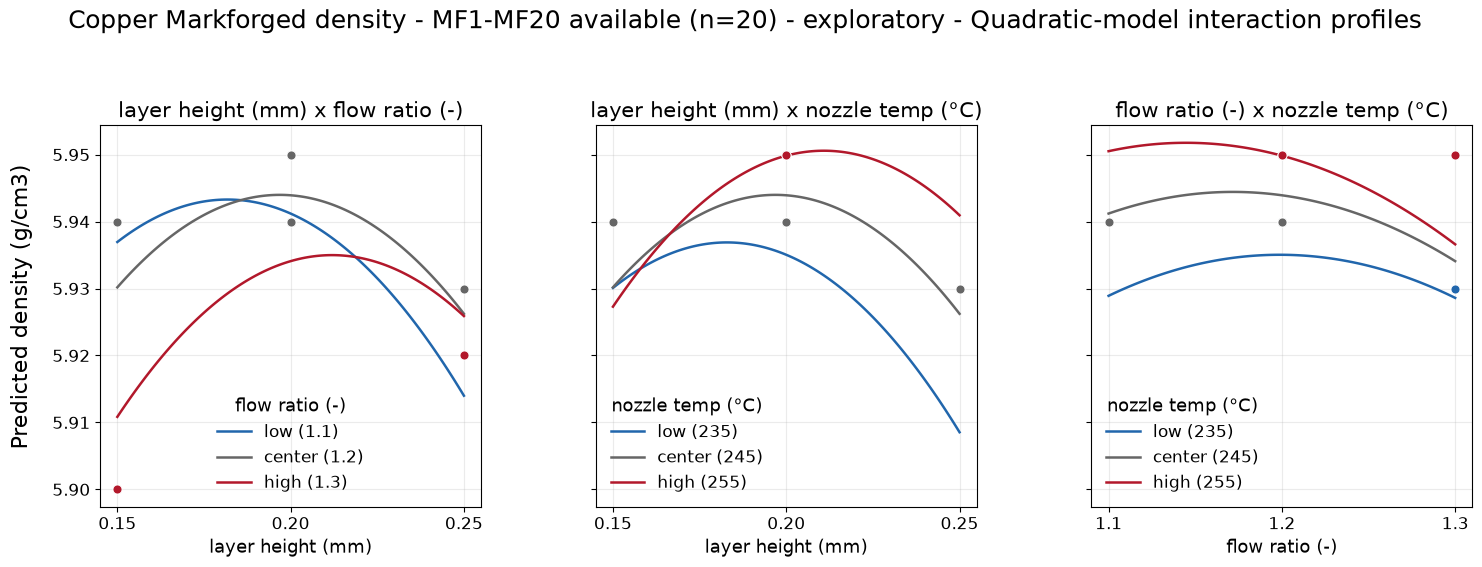

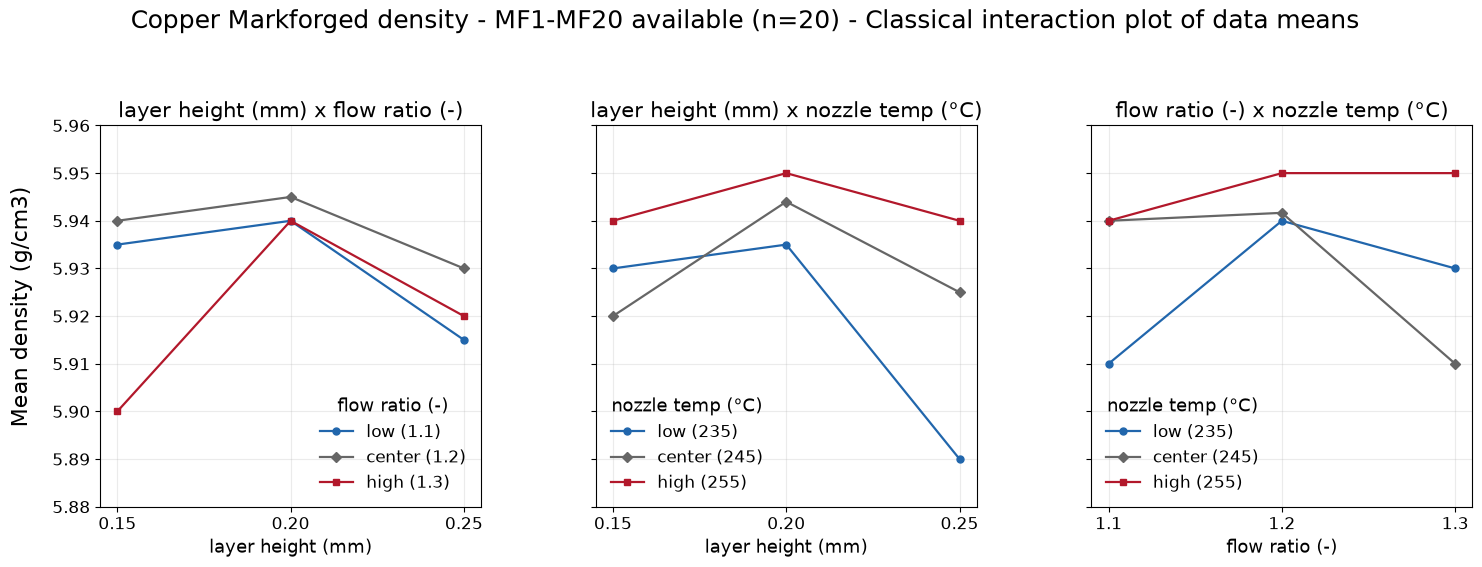

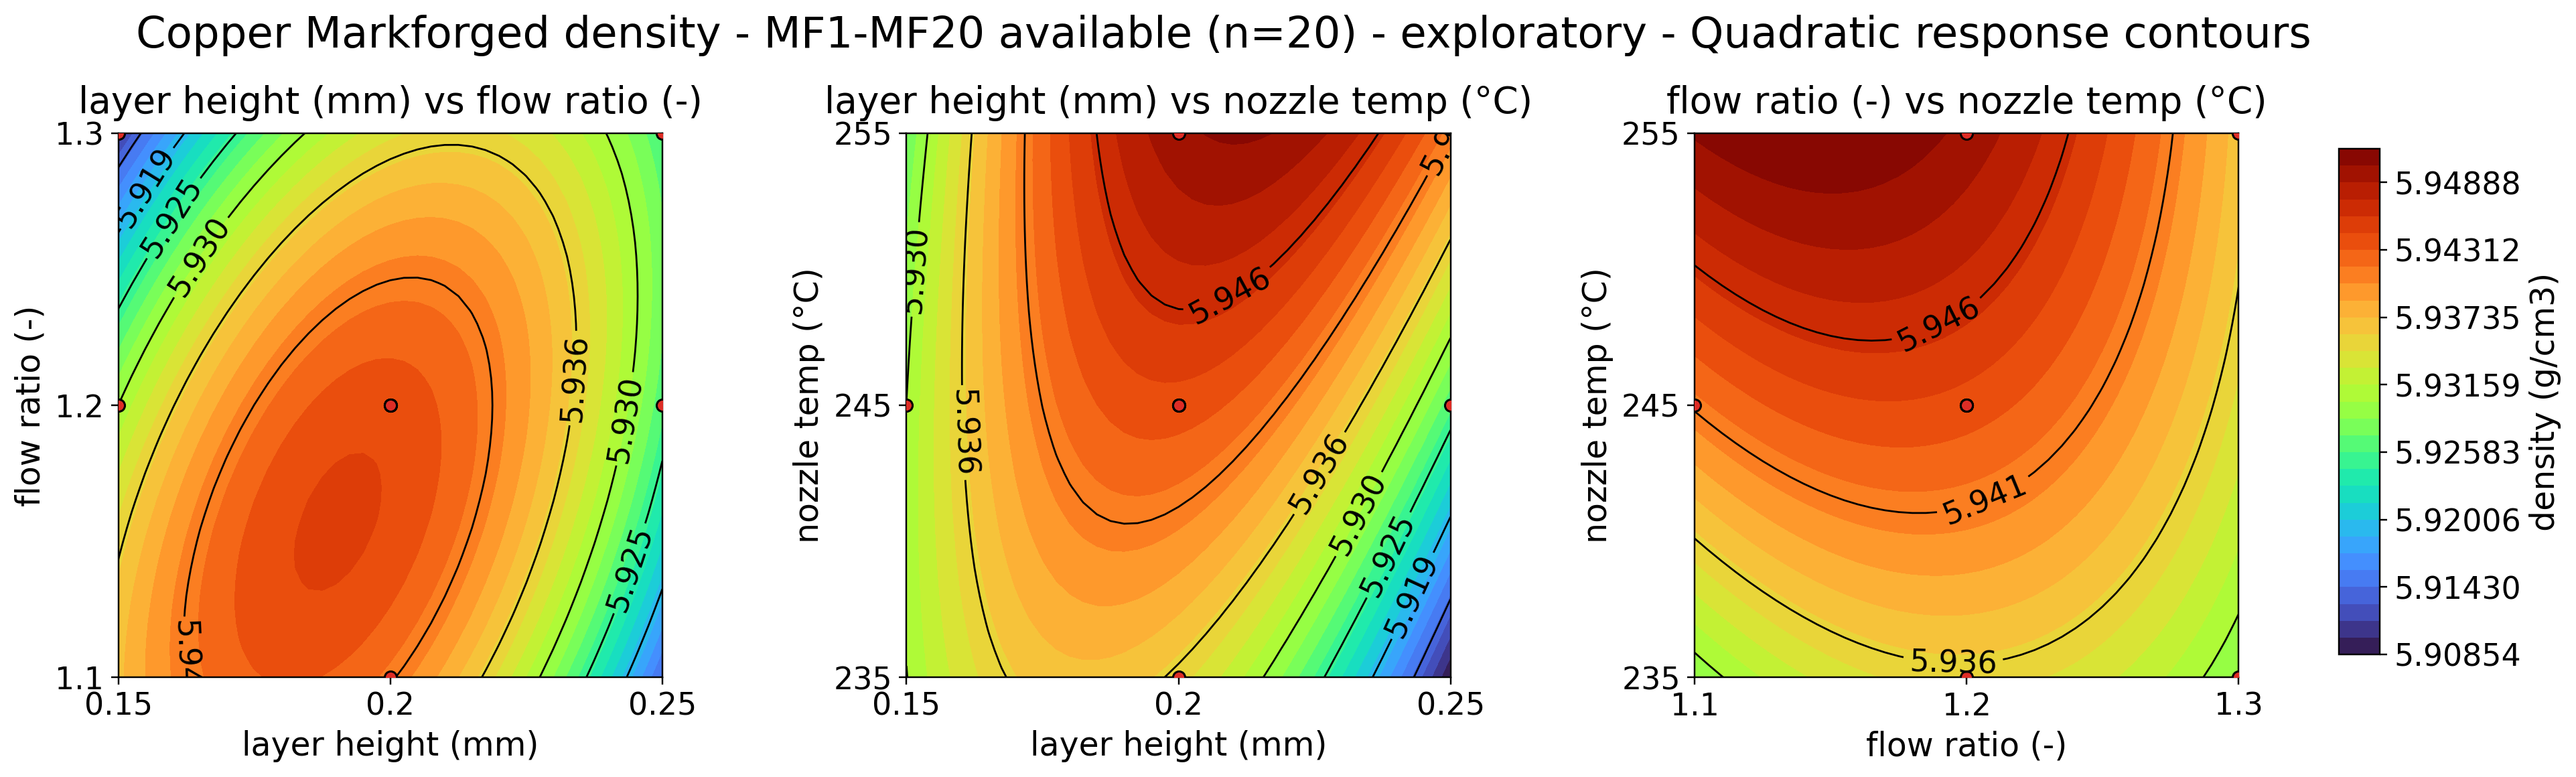

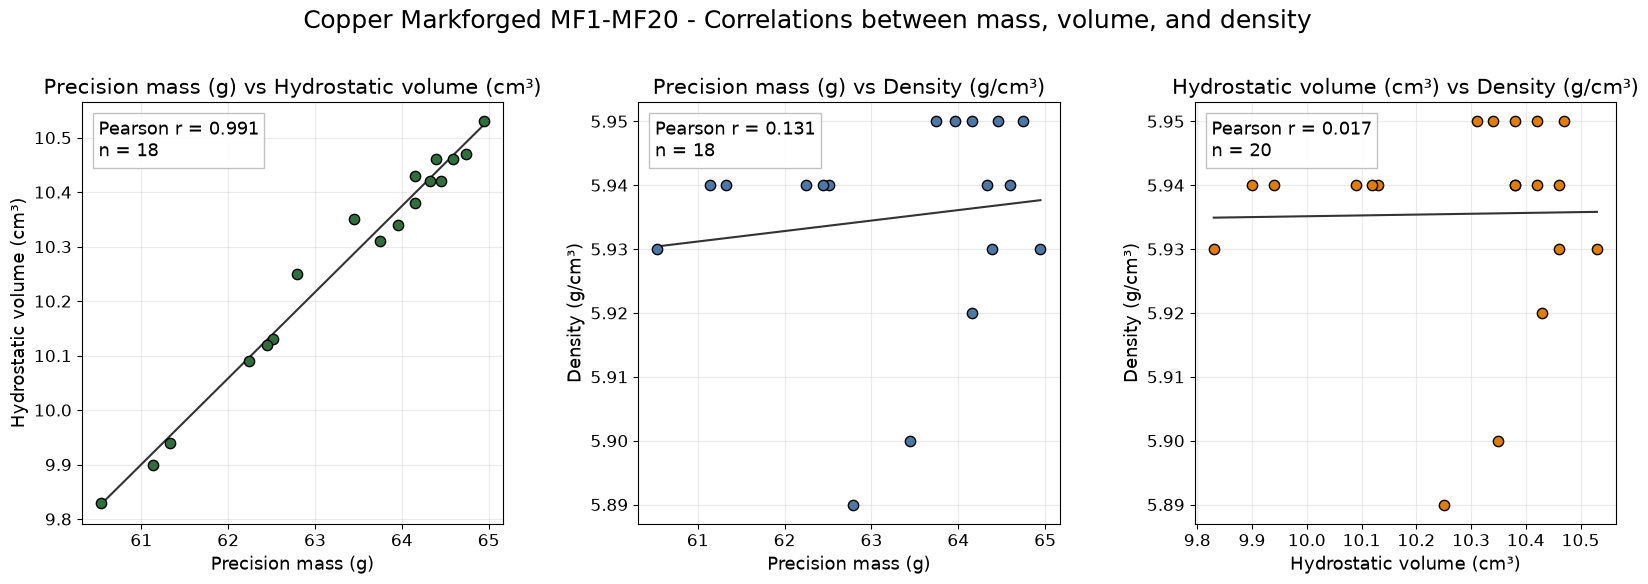

In [11]:
confirmation_coded_df = confirmation_df.copy()
confirmation_coded_df["A_layer_height"] = (
    confirmation_coded_df["layer_height_mm"] - LEVELS["A_layer_height"][0]
) / (LEVELS["A_layer_height"][1] - LEVELS["A_layer_height"][0])
confirmation_coded_df["B_flow_ratio"] = (
    confirmation_coded_df["flow_ratio"] - LEVELS["B_flow_ratio"][0]
) / (LEVELS["B_flow_ratio"][1] - LEVELS["B_flow_ratio"][0])
confirmation_coded_df["C_nozzle_temp"] = (
    confirmation_coded_df["nozzle_temperature_C"] - LEVELS["C_nozzle_temp"][0]
) / (LEVELS["C_nozzle_temp"][1] - LEVELS["C_nozzle_temp"][0])

augmented_response_df = pd.concat(
    [
        design_df[["Run", *FACTOR_COLUMNS, "mass_g", "density_g_cm3"]],
        confirmation_coded_df[["Run", *FACTOR_COLUMNS, "mass_g", "density_g_cm3"]],
    ],
    ignore_index=True,
)
display(augmented_response_df.round(4))

def run_augmented_markforged_plots(response, response_label):
    model_df = augmented_response_df[["Run", *FACTOR_COLUMNS, response]].copy()
    available_count = int(model_df[response].notna().sum())
    experiment = f"Copper Markforged {response_label} - MF1-MF20 available (n={available_count})"

    main_model = fit_main_effect_screening_model(
        model_df,
        response=response,
        factor_cols=FACTOR_COLUMNS,
    )
    _, pure_error_groups, pure_error_summary = calculate_pure_error_from_replicates(
        model_df,
        response=response,
        factor_cols=FACTOR_COLUMNS,
    )
    coefficient_table = build_term_significance_table(
        main_model,
        pure_error_summary=pure_error_summary,
        additional_alphas=[0.10],
        additional_pure_error_alphas=[0.10],
    )
    anova_table = build_model_anova_table(main_model)

    print(f"{response_label}: {available_count} measured runs included")
    display(main_model["info_df"].round(6))
    display(anova_table.round(6))
    display(coefficient_table.round(6))
    display(pure_error_groups.round(6))
    display(pure_error_summary.round(6))

    plot_model_anova(
        anova_table,
        response=response,
        experiment=experiment,
        variation_percent="density" in response.lower(),
    )
    plot_augmented_main_effects(
        main_model, LEVELS, experiment=experiment,
        figsize=(12, 5.8), square_axes=True,
    )
    plot_augmented_model_pareto(
        main_model,
        experiment=experiment,
        alpha=SIGNIFICANCE_ALPHA,
        pure_error_summary=pure_error_summary,
        legend_outside=False,
    )
    plot_screening_half_normal(main_model, experiment=experiment)
    plot_augmented_residuals(main_model, confirmation_run="", experiment=experiment)

    quadratic_model = fit_quadratic_response_surface(
        model_df,
        response=response,
        factor_cols=FACTOR_COLUMNS,
    )
    display(quadratic_model["info_df"].round(6))
    plot_quadratic_interaction_profiles(
        quadratic_model,
        LEVELS,
        experiment=f"{experiment} - exploratory",
        figsize=(15, 6.2), square_axes=True,
    )
    plot_three_level_interaction_means(
        model_df,
        response=response,
        factor_cols=FACTOR_COLUMNS,
        levels=LEVELS,
        experiment=experiment,
        figsize=(15, 6.2), square_axes=True,
    )
    plot_quadratic_surface_and_contour_pairs(
        quadratic_model,
        levels=LEVELS,
        fixed_level=0,
        experiment=f"{experiment} - exploratory",
        combine_pairs=True,
        contours_only=True,
        font_size=16,
        shared_colorbar=True,
    )
    return main_model, quadratic_model, pure_error_summary

augmented_mass_model, augmented_mass_quadratic_model, augmented_mass_pure_error = (
    run_augmented_markforged_plots("mass_g", "mass")
)
augmented_density_model, augmented_density_quadratic_model, augmented_density_pure_error = (
    run_augmented_markforged_plots("density_g_cm3", "density")
)

correlation_df = pd.concat(
    [
        design_df[["Run", "mass_g", "volume_cm3", "density_g_cm3"]],
        confirmation_df[["Run", "mass_g", "volume_cm3", "density_g_cm3"]],
    ],
    ignore_index=True,
)
correlation_pairs = [
    ("mass_g", "volume_cm3", "Precision mass (g)", "Hydrostatic volume (cm³)", "#2f6f3e"),
    ("mass_g", "density_g_cm3", "Precision mass (g)", "Density (g/cm³)", "#4c78a8"),
    ("volume_cm3", "density_g_cm3", "Hydrostatic volume (cm³)", "Density (g/cm³)", "#e17c05"),
]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 6.2))
for axis, (x_col, y_col, x_label, y_label, color) in zip(axes, correlation_pairs):
    pair_df = correlation_df.dropna(subset=[x_col, y_col]).copy()
    x_values = pair_df[x_col].to_numpy(dtype=float)
    y_values = pair_df[y_col].to_numpy(dtype=float)
    pearson_r = float(np.corrcoef(x_values, y_values)[0, 1])
    slope, intercept = np.polyfit(x_values, y_values, 1)
    line_x = np.linspace(x_values.min(), x_values.max(), 100)

    axis.scatter(x_values, y_values, s=55, color=color, edgecolor="black", zorder=3)
    axis.plot(line_x, slope * line_x + intercept, color="#333333", linewidth=1.5)
    axis.text(
        0.04, 0.96,
        f"Pearson r = {pearson_r:.3f}\nn = {len(pair_df)}",
        transform=axis.transAxes,
        va="top",
        bbox={"facecolor": "white", "edgecolor": "#bbbbbb", "alpha": 0.9},
    )
    axis.set_xlabel(x_label)
    axis.set_ylabel(y_label)
    axis.set_title(f"{x_label} vs {y_label}")
    axis.set_box_aspect(1)
    axis.grid(alpha=0.25)

fig.suptitle("Copper Markforged MF1-MF20 - Correlations between mass, volume, and density")
fig.subplots_adjust(left=0.06, right=0.99, bottom=0.14, top=0.84, wspace=0.32)
plt.show(block=False)


## 10. Interpretation and completion status

- The mass and density datasets are complete with 16 responses each.
- The confirmation phase contains three candidate prints at 0.21 mm, 1.18 flow ratio, and 255 deg C (MF17, MF19, and MF20), plus the same-batch center control MF18 at 0.20 mm, 1.20, and 245 deg C. Archimedes density is complete for MF17-MF20; only the precision masses of MF17 and MF19 remain pending.
- The original plots retain MF1-MF16 as the pre-confirmation reference. The separate augmented sensitivity section presents precision mass first (18 measured runs), followed by density (all 20 runs).
- The complete matrix supports a full quadratic response-surface model for both responses.
- The Pareto charts use an $\alpha=0.05$ threshold with residual and replicate-based degrees of freedom. The mass and density replicate thresholds use MF8, MF15, and MF16 with two pure-error degrees of freedom.
- Terms above the $\alpha=0.05$ threshold are potentially statistically relevant. Terms below it may still be practically relevant, but they are not statistically confirmed by the available data.
- The interaction-profile plots use exploratory full quadratic models. The complete mass and density models each have six residual degrees of freedom; interaction shapes should still be interpreted cautiously.
- The classical interaction plots connect observed means at the available low, center, and high settings. They are descriptive, average over the third factor, and do not by themselves establish interaction significance.
- The 3D surfaces and paired contour maps are slices through the exploratory quadratic models with the third factor held at its center setting. They visualize model predictions rather than additional measurements.
- Repeated balance readings of one specimen would estimate measurement uncertainty only; they must not be counted as independent print replicas.